# The 1504-cfg analysis: sGEVP matrix elements, single and double ratios (forward)

This notebook does all of `local_analysis/final_analysis/FIT_PLAN.md` part H (section 14) on the 1504-cfg set (section 13), using the methods of sections 1b, 4, 5 and 11. It starts from the raw 2pt and FF files and ends with every plot of the reports `sgevp_1504cfg_{pion,proton}.pdf`. The 2pt fits for $E_0$ and the gap (sections 3 and 3b) are in `matrix_element_analysis_1504cfg_2pt.ipynb` since 2026-11-20; section 5 reads $E_0$ from the file it saves.

- **Data:** Delta stream e, 724 cfg (the new pack), and Frontier stream d, 780 cfg (the 781-cfg files without cfg 3006, which has no FF). Forward frame, q = 0, pz 0-6, w 0-9, HYP 8, operator O = TXTX + TYTY - 2 XYXY.
- **sGEVP** (Khan et al. arXiv:2107.08960, eq. A7, with the summed GEVP of Bulava, Donnellan, Sommer, arXiv:1108.3774):
    - $K_{ab}(t) = \sum_{\tau=1}^{t-1} \left[\langle C_{ab}(t)\, O(\tau)\rangle - \langle C_{ab}(t)\rangle\langle O(\tau)\rangle\right]$, with all six operators;
    - $C(t)\,u = \lambda\, C(t_0)\,u$ is solved at every $t$ and in every jackknife sample;
    - $R(t) = u^\dagger K(t)\, u / \lambda - u^\dagger K(t_0)\, u$ and $M_{\rm eff}(t) = R(t+1) - R(t)$. This is made at $t_0$ = 2, 3, 4, 5, 6.
- **Fit:** $M_{\rm eff}(t) = A_w + B_w\, t\, e^{-\Delta E\, t}$, all ten w in one fit with one $\Delta E$ and $A_w < 0$. Every jackknife sample is fitted with its own covariance. It is fitted at every svdcut and every window of the B1 grid.
- **AIC and $t_0$ average, in every jackknife sample:** the weight is $w \sim \exp[-(\chi^2_j + 2k + 2N_{\rm cut})/2]$ over every pair ($t_0$, window). There are three variants:
    - fixed: the fixed window at every $t_0$;
    - B1: the full window grid;
    - B2: the last t only.
- **Ratios:**
    - double ratio $D = [M(p_z, w)/M(p_z, 0)]/[M(0, w)/M(0, 0)]$;
    - single ratio $S = M(p_z, w)/M(0, w) \times E_0(0)/E_0(p_z)$, where $E_0$ comes from the 2pt AIC fit of the same jackknife sample (`matrix_element_analysis_1504cfg_2pt.ipynb`).
- **2pt AIC:** in `matrix_element_analysis_1504cfg_2pt.ipynb`. It uses 2 or 3 states and every first and last t. The projected 2pt gives $E_0$; the G5G4 2pt with B and with U smearing give the gap.

Order, once for `hadron = "pion"` and once for `"proton"`: sections 0-2b and 4 here; then `matrix_element_analysis_1504cfg_2pt.ipynb` (its sections 0, 3, 3b); then sections 5 and 6 here. Everything is saved in `1504cfg_analysis/{hadron}_ncfg1504/`:

- `data/`: the 2pt per cfg and the M_eff of every t0;
- `sgevp_fits/`: every sGEVP fit (`pt2_aic_fits/`: the fits of the 2pt notebook);
- `results/`: the AIC averages, D and S (and E0, from the 2pt notebook);
- `plots/`: PNGs, and one PDF per plot section.

Section 4 skips every fit whose file is already saved. If it is stopped, run it again and it goes on where it stopped. Sections 2b and 6 only read and plot, and can be run again at any time once their inputs exist.

Run time with 13 workers, one hadron:

| Section | Time | Notes |
|---|---|---|
| 1 | under 1 min | about 10 GB of memory |
| 2 | about 1 min | |
| 4 | about 1.5 h | 5340 (pion) or 6000 (proton) jackknife fits, each 1504 sample fits + 11 fits of the mean |
| 5 | about 1 min | |
| 6 | about 2 min | |

Order: 0 settings, 1 read the data, 2 sGEVP $M_{\rm eff}$ (2b plots), [3 and 3b: `matrix_element_analysis_1504cfg_2pt.ipynb`], 4 sGEVP fits, 5 AIC and $t_0$ average, D and S, 6 plots of the fits (6a fitted $M_{\rm eff}$, 6b single and double ratio, 6c AIC weights, 6d svdcut scan).

## 0. Settings: hadron, data, operators, GEVP times, folders

In [3]:
import os
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"   #one BLAS thread per process: the many small fits of sections 3 and 4 run faster;  only works before numpy is imported (a fresh kernel)
os.environ["OMP_NUM_THREADS"] = "1"
import time
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import MaxNLocator, MultipleLocator
import gvar as gv
import lsqfit
from joblib import Parallel, delayed          #runs the fits of sections 3 and 4 in n_workers processes at once

#hadron
hadron = "pion"              #"pion" or "proton"
project = True               #proton only: True = positive-parity files
frame = "forward"            #this notebook does the forward frame only (q = 0)

#the data (FIT_PLAN.md section 13): Delta stream e, the 724-cfg pack, and Frontier stream d without cfg 3006 (it has no FF):  724 + 780 = 1504 cfg
#every data set of this list is read, and they are joined along the cfg axis in this order (as in matrix_element_analysis_sgevp.ipynb)
#  "dir": its folder;  "ncfg": the number of cfgs in the names of its 2pt files;  "ff_ncfg": the number of cfgs in the names of its FF files
#  "cfg_shift": added to its cfg numbers, so that the cfg numbers of two streams stay apart
#  "skip_cfg": cfgs of its 2pt files that are left out;  [] = none
data_sets = [{"name": "delta_stream_e", "dir": "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta", "ncfg": 724, "ff_ncfg": 800, "cfg_shift": 0, "skip_cfg": []},
             {"name": "frontier_stream_d", "dir": "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd", "ncfg": 781, "ff_ncfg": 798, "cfg_shift": 100000, "skip_cfg": [3006]}]
ncfg = 0                     #the total number of cfgs: it goes in the names of the saved files
for data in data_sets:
    ncfg = ncfg + data["ncfg"] - len(data["skip_cfg"])
Lt = 96
Ls = 32
hyp = 8                      #HYP steps of the gluon operator

#the six operators of the files, (smear, gamma):  smear 0 = B = [4.5, 2.25, 0.8], 1 = U = [1.5, 1.5, 0];  gamma 0 = G5, 1 = G5G4, 2 = G3G5
op_basis = [(0,0),(0,1),(0,2),(1,0),(1,1),(1,2)]
smear_names = ["B", "U"]
gamma_names = ["G5", "G5G4", "G3G5"]
op_labels = [smear_names[s] + gamma_names[g] for s, g in op_basis]     #["BG5", "BG5G4", "BG3G5", "UG5", "UG5G4", "UG3G5"]

#sGEVP (FIT_PLAN.md sections 4 and 11):  the operators (the same at every pz) and the GEVP times t0;  M_eff is made at every t, also below t0
sgevp_ops = ["BG5", "BG5G4", "BG3G5", "UG5", "UG5G4", "UG3G5"]          #all six
sgevp_t0_list = [2, 3, 4, 5, 6]                                          #section 2 makes M_eff at each of these t0
#the t0 of each pz that are fitted (section 4) and averaged over (section 5)
#pion pz 6 leaves out t0 6 (FIT_PLAN.md section 9, "Decision"): there M(w) rises again at large w, M(w 9)/M(w 0) = 0.735
if hadron == "pion":
    sgevp_t0_of_pz = {0: [2, 3, 4, 5, 6], 1: [2, 3, 4, 5, 6], 2: [2, 3, 4, 5, 6], 3: [2, 3, 4, 5, 6], 4: [2, 3, 4, 5, 6], 5: [2, 3, 4, 5, 6], 6: [2, 3, 4, 5]}
else:
    sgevp_t0_of_pz = {0: [2, 3, 4, 5, 6], 1: [2, 3, 4, 5, 6], 2: [2, 3, 4, 5, 6], 3: [2, 3, 4, 5, 6], 4: [2, 3, 4, 5, 6], 5: [2, 3, 4, 5, 6], 6: [2, 3, 4, 5, 6]}

#the projected 2pt for E0 (FIT_PLAN.md section 1b, "GEVP and the projected 2pt"):  the ratio basis of each pz, one GEVP vector from the mean 2pt matrix, GEVP times t0, t_ref
#the same as pion_default and proton_default of matrix_element_analysis_fit_per_pz.ipynb
pion_default = {0: {"basis": ["BG5G4", "UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                1: {"basis": ["UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                2: {"basis": ["BG5", "UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                3: {"basis": ["UG3G5"], "t0": 3, "t_ref": 5},
                4: {"basis": ["UG3G5"], "t0": 3, "t_ref": 5},
                5: {"basis": ["BG5G4", "UG5G4"], "t0": 3, "t_ref": 5},
                6: {"basis": ["BG3G5", "UG3G5"], "t0": 3, "t_ref": 5}}
proton_default = {0: {"basis": ["UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                  1: {"basis": ["UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                  2: {"basis": ["UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                  3: {"basis": ["UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                  4: {"basis": ["UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                  5: {"basis": ["UG5G4"], "t0": 3, "t_ref": 5},
                  6: {"basis": ["BG3G5"], "t0": 3, "t_ref": 5}}
if hadron == "pion":
    pt2_gevp_choice = pion_default
else:
    pt2_gevp_choice = proton_default

#the fits of sections 3 and 4
n_workers = 13               #processes that fit at the same time (this Mac has 18 cores);  1 = one fit after the other, in this kernel
#plots
show_plots = True            #True = every figure is also drawn in the notebook;  False = only saved (PNG files and one PDF per plot section)

#directories and names
analysis_dir = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/1504cfg_analysis"
pt2_name = "2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_{frame}_q{qx}_{qy}_{qz}_{pt2_type}_fb_tsep20_3072src_ncfg{ncfg}_{hadron}.h5"
ff_name = "FF_hyp0-8_w0-9_q{qx}_{qy}_{qz}_ncfg{ncfg}.h5"
if hadron == "pion":
    hadron_tag = "pion"
elif project:
    hadron_tag = "proton_projected"
else:
    hadron_tag = "proton"
c_sign = {"pion": -1, "proton": +1}[hadron]      #to make Cij positive definite, the pion is multiplied by -1
#everything this notebook saves for this hadron goes in save_dir
save_dir = os.path.join(analysis_dir, f"{hadron}_ncfg{ncfg}")
#the files:  the name says what is in them
pt2_data_file = os.path.join(save_dir, "data", f"pt2_projected_G5G4BU_forward_q0_0_0_ncfg{ncfg}_{hadron_tag}.h5")            #section 1: the 2pt of every cfg
meff_file = os.path.join(save_dir, "data", f"sgevp_meff_forward_q0_0_0_six_t0{'-'.join(str(t0) for t0 in sgevp_t0_list)}allt_hyp{hyp}_ncfg{ncfg}_{hadron_tag}.h5")     #section 2
pt2_result_file = os.path.join(save_dir, "results", f"pt2_aic_E0_gap_forward_q0_0_0_ncfg{ncfg}_{hadron_tag}.h5")          #made by matrix_element_analysis_1504cfg_2pt.ipynb (its section 3): E0 and the gap of every sample;  section 5 reads E0 from it
sgevp_fit_dir = os.path.join(save_dir, "sgevp_fits")                                                                       #section 4: one file per fit
sgevp_result_file = os.path.join(save_dir, "results", f"sgevp_aic_t0avg_D_S_forward_q0_0_0_six_hyp{hyp}_ncfg{ncfg}_{hadron_tag}.h5")     #section 5
plot_dir = os.path.join(save_dir, "plots")
plot_title = f"{hadron_tag}, forward, {ncfg} cfg"                #the start of every plot title

assert frame == "forward", "this notebook does the forward frame only"
for name in sgevp_ops:
    assert name in op_labels, f"sgevp_ops: {name} is not one of {op_labels}"
for pz in sgevp_t0_of_pz:
    for t0 in sgevp_t0_of_pz[pz]:
        assert t0 in sgevp_t0_list, f"pz = {pz}: t0 {t0} is not in sgevp_t0_list"
for pz in pt2_gevp_choice:
    for name in pt2_gevp_choice[pz]["basis"]:
        assert name in op_labels, f"pz = {pz}: {name} is not one of {op_labels}"


#======== functions used by several cells (the first six as in matrix_element_analysis_sgevp.ipynb, solve_gevp as in matrix_element_analysis_fit_per_pz.ipynb) ========
def pt2_file(data, q_i, pt2_type):
    #the 2pt file of one data set of data_sets
    return os.path.join(data["dir"], pt2_name.format(frame=frame, qx=q_i[0], qy=q_i[1], qz=q_i[2], pt2_type=pt2_type, ncfg=data["ncfg"], hadron=hadron_tag))


def read_joined(q_i, pt2_type, name):
    #one dataset of the 2pt files that has an entry per cfg, e.g. "pt2_forward", "t_src_list", "cfg_list":  read from every data set and joined along the cfg axis
    parts = []
    for data in data_sets:
        file = pt2_file(data, q_i, pt2_type)
        assert os.path.exists(file), f"no such file: {file}"
        with h5py.File(file, "r") as f:
            part = f[name][()]
            cfg_of_file = f["cfg_list"][()]
        assert part.shape[0] == data["ncfg"], f"{file}: {part.shape[0]} cfgs, but data_sets says {data['ncfg']}"
        assert np.isin(data["skip_cfg"], cfg_of_file).all(), f"{file}: a cfg of skip_cfg is not in this file"
        part = part[~np.isin(cfg_of_file, data["skip_cfg"])]     #leave out the cfgs of skip_cfg
        if name == "cfg_list":
            part = part + data["cfg_shift"]     #the cfg numbers of two streams stay apart
        parts.append(part)
    return np.concatenate(parts)


def read_shared(q_i, pt2_type, name):
    #one dataset of the 2pt files that has to be the same in every data set, e.g. "pz_list", "smear_list"
    for data in data_sets:
        file = pt2_file(data, q_i, pt2_type)
        assert os.path.exists(file), f"no such file: {file}"
        with h5py.File(file, "r") as f:
            value = f[name][()]
        if data is data_sets[0]:
            first = value
        assert np.array_equal(value, first), f"{name} of {data['name']} is not the same as in {data_sets[0]['name']}"
    return first


def jk(data, jk_axis=0):
    #jackknife mean and error
    n = data.shape[jk_axis]
    data = np.moveaxis(data, jk_axis, 0)
    mean = np.mean(data, axis=0)
    err = np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))
    return mean, err


def jackknife(x):
    #per-cfg data (cfg, ...) -> jackknife samples (jk, ...)
    n_cfg = x.shape[0]
    return (x.sum(axis=0) - x) / (n_cfg - 1)


def op_matrix(pt2, basis):
    #(cfg, smear_snk, smear_src, gamma_snk, gamma_src, ...) -> (cfg, op_snk, op_src, ...)
    n_op = len(basis)
    Cij = np.zeros(pt2.shape[:1] + (n_op, n_op) + pt2.shape[5:], dtype=complex)
    for a, (s_snk, g_snk) in enumerate(basis):
        for b, (s_src, g_src) in enumerate(basis):
            Cij[:, a, b] = pt2[:, s_snk, s_src, g_snk, g_src]
    return Cij


def solve_gevp(C_matrix, t0_pz):
    #one pz:  C_matrix (op, op, tsep): eigenvalues (state, tsep) and eigenvectors (state, tsep, op), largest eigenvalue first, NaN at tsep <= t0_pz
    n_op, _, n_tsep = C_matrix.shape
    eigen_val = np.full((n_op, n_tsep), np.nan)
    eigen_vec = np.full((n_op, n_tsep, n_op), np.nan, dtype=complex)
    L_inv = np.linalg.inv(np.linalg.cholesky(C_matrix[:, :, t0_pz]))
    for t in range(t0_pz + 1, n_tsep):
        M = L_inv @ C_matrix[:, :, t] @ L_inv.conj().T
        w, u = np.linalg.eigh(M)
        v = L_inv.conj().T @ u
        order = np.argsort(w)[::-1]
        eigen_val[:, t] = w[order]
        eigen_vec[:, t] = v[:, order].T
    return eigen_val, eigen_vec


def save_figure(fig, pdf, folder, name):
    #a figure of the plot cells:  saved as PNG in plot_dir/folder and as a page of the open PDF file pdf, then drawn in the notebook (show_plots) or closed
    os.makedirs(os.path.join(plot_dir, folder), exist_ok=True)
    fig.savefig(os.path.join(plot_dir, folder, f"{name}_{hadron_tag}_ncfg{ncfg}.png"), dpi=110)
    pdf.savefig(fig)
    if show_plots:
        plt.show()
    else:
        plt.close(fig)


for data in data_sets:
    print(f"data set {data['name']}: {data['ncfg']} cfg, {len(data['skip_cfg'])} left out, cfg numbers + {data['cfg_shift']}, folder {data['dir']}")
print("hadron", hadron_tag, "|", ncfg, "cfg in total | hyp", hyp, "| sGEVP operators", " ".join(sgevp_ops), "| sGEVP t0", sgevp_t0_list)
print("t0 averaged per pz:", ";  ".join(f"pz {pz}: {' '.join(str(t0) for t0 in sgevp_t0_of_pz[pz])}" for pz in sgevp_t0_of_pz))
print("projected 2pt (E0):", ";  ".join(f"pz {pz}: {' '.join(pt2_gevp_choice[pz]['basis'])}, t0 {pt2_gevp_choice[pz]['t0']}, t_ref {pt2_gevp_choice[pz]['t_ref']}" for pz in pt2_gevp_choice))
print("folder", save_dir, "|", n_workers, "workers")

data set delta_stream_e: 724 cfg, 0 left out, cfg numbers + 0, folder /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta
data set frontier_stream_d: 781 cfg, 1 left out, cfg numbers + 100000, folder /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd
hadron pion | 1504 cfg in total | hyp 8 | sGEVP operators BG5 BG5G4 BG3G5 UG5 UG5G4 UG3G5 | sGEVP t0 [2, 3, 4, 5, 6]
t0 averaged per pz: pz 0: 2 3 4 5 6;  pz 1: 2 3 4 5 6;  pz 2: 2 3 4 5 6;  pz 3: 2 3 4 5 6;  pz 4: 2 3 4 5 6;  pz 5: 2 3 4 5 6;  pz 6: 2 3 4 5
projected 2pt (E0): pz 0: BG5G4 UG5 UG5G4, t0 3, t_ref 5;  pz 1: UG5 UG5G4, t0 3, t_ref 5;  pz 2: BG5 UG5G4 UG3G5, t0 3, t_ref 5;  pz 3: UG3G5, t0 3, t_ref 5;  pz 4: UG3G5, t0 3, t_ref 5;  pz 5: BG5G4 UG5G4, t0 3, t_ref 5;  pz 6: BG3G5 UG3G5, t0 3, t_ref 5
folder /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/1504cfg_analysis/pion_ncfg1504 | 13 workers


## 1. Read the data: K(t) and C(t) of the six operators, the projected 2pt and the G5G4 2pt of every cfg

In [4]:
#======== read the 2pt and FF files:  pt3_summed(t) and C(t) of the six operators (sGEVP, kept in memory), the projected 2pt and the G5G4 2pt of every cfg (saved) ========
#pt3_summed_ab(t) = sum over tau = 1 .. t-1 of [<C_ab(t) O(tau)> - <C_ab(t)><O(tau)>]:  the 3pt of method 1 summed over the operator time (FIT_PLAN.md section 1b, "sGEVP")
#  per source: the operator summed over the slices strictly between source and sink, times the 2pt of that source;  then the mean over the sources
#  vacuum term: the jackknife mean of the 2pt times the jackknife mean of the summed operator, over the same slices
#C_ab(t): the 2pt matrix, mean over the sources, its Hermitian part;  a = sink operator, b = source operator
#projected 2pt (for E0): c_sign v0^dag C(t) v0 of every cfg, v0 = the GEVP ground-state vector of the mean 2pt matrix of each half (pt2_gevp_choice);  the two halves averaged
#G5G4 2pt (for the gap): the diagonal G5G4-G5G4 2pt, no GEVP, B smearing at both ends and U at both ends;  the mean over the sources of Re C, times c_sign;  the two halves averaged
half_sign = {"forward": +1, "backward": -1}     #operator at t_src + tau (forward half), t_src - tau (backward half)
q0 = (0, 0, 0)
time_start = time.time()
cfg_list = read_joined(q0, "C3input", "cfg_list")          #(cfg,): the cfgs of all data sets, cfg_shift added
pz_list = read_shared(q0, "C3input", "pz_list")             #(pz,)
smear_list = read_shared(q0, "C3input", "smear_list")       #(smear, 3): rho_T, rho_z, boost fraction
t_src_list = read_joined(q0, "C3input", "t_src_list")       #(cfg, t_src): the slice of each source, shifts per cfg
n_cfg, n_tsrc = t_src_list.shape
n_pz = len(pz_list)
assert n_cfg == ncfg, f"{n_cfg} cfgs read, but data_sets gives {ncfg}"
assert len(np.unique(cfg_list)) == len(cfg_list), "two data sets have a cfg number in common: give one of them another cfg_shift"
assert np.allclose(smear_list, [[4.5, 2.25, 0.8], [1.5, 1.5, 0.0]]), f"smear_list {smear_list.tolist()}: not B, U"
for data in data_sets:
    with h5py.File(pt2_file(data, q0, "C3input"), "r") as f:
        assert list(f.attrs["gamma_list"]) == gamma_names, f"{data['name']}: the gammas of the file are not {gamma_names}"

#---- the gluon operator O3 = TXTX + TYTY - 2 XYXY:  FF (cfg, munu, rhosig, hyp, w, t), munu order XY, YZ, XZ, XT, YT, ZT
#every data set has its own FF file;  the cfgs of its 2pt file are looked up in it by their cfg number, then the data sets are joined in the same order as the 2pt
O_parts = []
for data in data_sets:
    with h5py.File(pt2_file(data, q0, "C3input"), "r") as f:
        cfg_of_set = f["cfg_list"][()]              #the 2pt cfgs of this data set, its own numbers without cfg_shift
    cfg_of_set = cfg_of_set[~np.isin(cfg_of_set, data["skip_cfg"])]     #leave out the cfgs of skip_cfg
    FF_file = os.path.join(data["dir"], ff_name.format(qx=0, qy=0, qz=0, ncfg=data["ff_ncfg"]))
    print("reading", FF_file)
    assert os.path.exists(FF_file), f"no such file: {FF_file}"
    with h5py.File(FF_file, "r") as f:
        FF_cfg = f["cfg_list"][()]
        assert np.isin(cfg_of_set, FF_cfg).all(), f"{data['name']}: some 2pt cfgs are not in the FF file"
        idx = np.searchsorted(FF_cfg, cfg_of_set)   #the 2pt cfgs are not the first FF cfgs
        assert np.array_equal(FF_cfg[idx], cfg_of_set)
        ihyp = list(f["hyp_list"][()]).index(hyp)
        if data is data_sets[0]:
            w_list = f["w_list"][()]
        assert np.array_equal(f["w_list"][()], w_list), f"{data['name']}: other w than {data_sets[0]['name']}"
        TXTX = f["FF"][idx, 3, 3, ihyp]
        TYTY = f["FF"][idx, 4, 4, ihyp]
        XYXY = f["FF"][idx, 0, 0, ihyp]
    O_parts.append(TXTX + TYTY - 2 * XYXY)          #(cfg of this set, w, t)
O = np.concatenate(O_parts)                         #(cfg, w, t)
n_w = len(w_list)

#---- C, pt3_summed, the projected 2pt and the G5G4 2pt of each half
i_cfg = np.arange(n_cfg)[:, None, None]
C_jk = {}       #C_jk[half]: (jk, pz, t, op, op), c_sign in, Hermitian part
pt3_summed_jk = {}      #pt3_summed_jk[half]: (jk, w, pz, t, op, op), the 3pt summed over tau = 1 .. t-1, c_sign in
v0 = {}         #v0[half]: (pz, op), the GEVP vector of the projected 2pt, all six operators (0 for the ones this pz does not use)
C2_projected = {}               #C2_projected[half]: (cfg, pz, t), complex, c_sign in
C2_G5G4 = {"B": {}, "U": {}}    #C2_G5G4[smear][half]: (cfg, pz, t), real, c_sign in
for half in half_sign:
    for data in data_sets:
        print("reading", pt2_file(data, q0, "C3input"), half)
    raw = read_joined(q0, "C3input", f"pt2_{half}")             #(cfg, smear, smear, gamma, gamma, t_src, pz, t)
    #the G5G4 2pt, B-B and U-U
    ig = gamma_names.index("G5G4")
    for s, smear in enumerate(smear_names):
        C2_G5G4[smear][half] = c_sign * raw[:, s, s, ig, ig].real.mean(axis=1)            #(cfg, pz, t): mean over the sources
    Cij = op_matrix(raw, op_basis)                              #(cfg, op, op, t_src, pz, t)
    del raw
    n_tsep = Cij.shape[-1]
    C_cfg = Cij.mean(axis=3)                                    #(cfg, op, op, pz, t): mean over the sources
    #the projected 2pt:  the GEVP of the mean 2pt matrix of this half, C(t_ref) v = lambda C(t0) v on the operators of each pz, v0 = the ground state (largest lambda), v0^dag C(t0) v0 = 1
    C_mean = c_sign * C_cfg.mean(axis=0)                        #(op, op, pz, t)
    C_mean = 0.5 * (C_mean + C_mean.conj().swapaxes(0, 1))      #Hermitian
    v0[half] = np.zeros((n_pz, len(op_labels)), dtype=complex)
    for ipz, pz in enumerate(pz_list):
        use = [op_labels.index(name) for name in pt2_gevp_choice[int(pz)]["basis"]]
        eigen_val, eigen_vec = solve_gevp(C_mean[np.ix_(use, use)][:, :, ipz], pt2_gevp_choice[int(pz)]["t0"])
        v0[half][ipz, use] = eigen_vec[0, pt2_gevp_choice[int(pz)]["t_ref"]]
    C2_projected[half] = c_sign * np.einsum("pa,cabpT,pb->cpT", v0[half].conj(), C_cfg, v0[half])     #(cfg, pz, t)
    #C and pt3_summed of the sGEVP
    C = np.moveaxis(c_sign * jackknife(C_cfg), (1, 2), (-2, -1))                #(jk, pz, t, op, op)
    C_jk[half] = 0.5 * (C + np.conj(np.swapaxes(C, -1, -2)))                    #Hermitian part
    t_op = (t_src_list[:, :, None] + half_sign[half] * np.arange(n_tsep)) % Lt  #(cfg, t_src, tau): the slice of the operator
    O_tau = O[i_cfg, :, t_op]                                   #(cfg, t_src, tau, w): numpy puts w last here
    O_sum = np.zeros_like(O_tau)                                #(cfg, t_src, t, w): O summed over tau = 1 .. t-1
    for t in range(n_tsep):
        O_sum[:, :, t] = O_tau[:, :, 1:t].sum(axis=2)
    connected = np.einsum("cabspt,cstw->cabwpt", Cij, O_sum, optimize=True) / n_tsrc            #(cfg, op, op, w, pz, t): source by source, mean over the sources
    vacuum = np.einsum("cabpt,ctw->cabwpt", jackknife(C_cfg), jackknife(O_sum.mean(axis=1)), optimize=True)    #(jk, op, op, w, pz, t)
    pt3_summed_jk[half] = np.moveaxis(c_sign * (jackknife(connected) - vacuum), (1, 2), (-2, -1))      #(jk, w, pz, t, op, op)
    del Cij, C_cfg, C, O_tau, O_sum, connected, vacuum

#---- the 2pt of every cfg, the two halves averaged:  the three 2pt sets of matrix_element_analysis_1504cfg_2pt.ipynb (section 3)
pt2_cfg = {}            #pt2_cfg[name]: (cfg, pz, t), real
pt2_cfg["projected"] = 0.5 * (C2_projected["forward"] + C2_projected["backward"]).real
for smear in smear_names:
    for half in half_sign:      #a diagonal 2pt: both halves have to be positive before they are averaged
        mean = C2_G5G4[smear][half].mean(axis=0)
        print(f"G5G4 {smear}-{smear}, {half}: mean C(t) > 0 at every pz and t 1-12: {bool((mean[:, 1:13] > 0).all())};  C(0) > 0 at every pz: {bool((mean[:, 0] > 0).all())}")
    pt2_cfg[f"G5G4{smear}"] = 0.5 * (C2_G5G4[smear]["forward"] + C2_G5G4[smear]["backward"])

#---- save the 2pt of every cfg
os.makedirs(os.path.dirname(pt2_data_file), exist_ok=True)
if os.path.exists(pt2_data_file):
    print("replacing", pt2_data_file)
with h5py.File(pt2_data_file, "w") as f:
    for name in pt2_cfg:
        f[f"C2_{name}_fb_cfg"] = pt2_cfg[name]     #(cfg, pz, t): the two halves averaged, c_sign in
    f["v0_forward"] = v0["forward"]                #(pz, op): the GEVP vectors of the projected 2pt
    f["v0_backward"] = v0["backward"]
    f["projected_basis"] = [" ".join(pt2_gevp_choice[int(pz)]["basis"]) for pz in pz_list]
    f["projected_t0"] = [pt2_gevp_choice[int(pz)]["t0"] for pz in pz_list]
    f["projected_t_ref"] = [pt2_gevp_choice[int(pz)]["t_ref"] for pz in pz_list]
    f["cfg_list"] = cfg_list
    f["pz_list"] = pz_list
    f["op_labels"] = op_labels
    f["smear_list"] = smear_list
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
    f["data_sets"] = [data["name"] for data in data_sets]
    f["data_set_ncfg"] = [data["ncfg"] for data in data_sets]
    f["data_set_cfg_shift"] = [data["cfg_shift"] for data in data_sets]
    f["data_set_skip_cfg"] = [" ".join(str(c) for c in data["skip_cfg"]) for data in data_sets]
print("saved", pt2_data_file)

#---- save the 2pt and the summed 3pt with the jackknife index and the operator indices (a = sink, b = source), both halves, in two files:  what the sGEVP uses;  nothing new is computed here
#the 2pt matrix
pt2_6x6_file = os.path.join(save_dir, "data", f"pt2_6x6_jk_forward_q0_0_0_ncfg{ncfg}_{hadron_tag}.h5")
if os.path.exists(pt2_6x6_file):
    print("replacing", pt2_6x6_file)
with h5py.File(pt2_6x6_file, "w") as f:
    for half in half_sign:
        f[f"pt2_jk_{half}"] = C_jk[half]                    #(jk, pz, t, a, b): the 2pt matrix, mean over the sources, c_sign in, Hermitian part
    f["cfg_list"] = cfg_list                                #(cfg,): jackknife sample j leaves out cfg j of this list
    f["pz_list"] = pz_list
    f["op_labels"] = op_labels                              #the order of the indices a, b
    f["smear_list"] = smear_list
    f["c_sign"] = c_sign
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
    f["data_sets"] = [data["name"] for data in data_sets]
    f["data_set_skip_cfg"] = [" ".join(str(cfg) for cfg in data["skip_cfg"]) for data in data_sets]
print("saved", pt2_6x6_file)
#the summed 3pt
pt3_summed_6x6_file = os.path.join(save_dir, "data", f"pt3_summed_6x6_jk_forward_q0_0_0_hyp{hyp}_ncfg{ncfg}_{hadron_tag}.h5")
if os.path.exists(pt3_summed_6x6_file):
    print("replacing", pt3_summed_6x6_file)
with h5py.File(pt3_summed_6x6_file, "w") as f:
    for half in half_sign:
        f[f"pt3_summed_jk_{half}"] = pt3_summed_jk[half]    #(jk, w, pz, t, a, b): the 3pt of method 1 summed over tau = 1 .. t-1, c_sign in
    f["cfg_list"] = cfg_list                                #(cfg,): jackknife sample j leaves out cfg j of this list
    f["pz_list"] = pz_list
    f["w_list"] = w_list
    f["op_labels"] = op_labels                              #the order of the indices a, b
    f["smear_list"] = smear_list
    f["c_sign"] = c_sign
    f["hyp"] = hyp
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
    f["data_sets"] = [data["name"] for data in data_sets]
    f["data_set_skip_cfg"] = [" ".join(str(cfg) for cfg in data["skip_cfg"]) for data in data_sets]
print("saved", pt3_summed_6x6_file)

#check: the summed ratio pt3_summed/C of one operator at t 8, w 0, both halves (single-operator numbers, before any GEVP)
for half in half_sign:
    a = op_labels.index(sgevp_ops[0])
    m, e = jk(pt3_summed_jk[half][:, 0, :, 8, a, a].real / C_jk[half][:, :, 8, a, a].real)
    print(f"{half}, {op_labels[a]}: pt3_summed(8)/C(8) at w 0, pz {' '.join(str(int(p)) for p in pz_list)}:", " ".join(f"{x:+.3f}({y * 1e3:.0f})" for x, y in zip(m, e)))
print(f"{n_cfg} cfg, {n_pz} pz, {n_w} w, t 0-{n_tsep - 1};  {time.time() - time_start:.0f} s")

reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/FF_hyp0-8_w0-9_q0_0_0_ncfg800.h5
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd/FF_hyp0-8_w0-9_q0_0_0_ncfg798.h5
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg724_pion.h5 forward
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg781_pion.h5 forward
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg724_pion.h5 backward
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd/2pt

## 2. sGEVP: $M_{\rm eff}(t)$ at every $t_0$, and the end of the signal

In [3]:
#======== sGEVP:  R(t) = u^dag pt3_summed(t) u / lambda(t, t0) - u^dag pt3_summed(t0) u,   M_eff(t) = R(t+1) - R(t),  at every t0 of sgevp_t0_list;  saved ========
#(section 2 of matrix_element_analysis_sgevp.ipynb, with the operators sgevp_ops at every pz, M_eff also below t0, and a loop over t0)
#u, lambda: the ground state of the GEVP C(t) u = lambda C(t0) u, solved again at every t and for every jackknife sample, with u^dag C(t0) u = 1
#  t > t0: the ground state has the largest eigenvalue, lambda = exp(-E0 (t - t0)) < 1
#  t < t0: the ground state has the smallest eigenvalue, lambda = exp(E0 (t0 - t)) > 1;  R(t) is the same formula
#  R(t0) = 0.  Each half has its own GEVP;  R is the mean of the two halves.  Re[u^dag pt3_summed u] = u^dag (pt3_summed + pt3_summed^dag)/2 u: its Hermitian part
#the end of the signal of each pz (FIT_PLAN.md section 7):  the last t up to which |M_eff(w 0)| / error >= signal_sn_min at every t from signal_from_t on, at most signal_t_cap,
#  at t0 = signal_t0;  it is found before any fit, and the window grids of section 4 run up to it (the same grids at every t0)
signal_t0 = 2
signal_from_t = 2
signal_sn_min = 2.0
signal_t_cap = 16
time_start = time.time()
n_jk = C_jk["forward"].shape[0]
use = [op_labels.index(name) for name in sgevp_ops]            #the operators of the sGEVP, the same at every pz
meff_jk = {}            #meff_jk[t0]: (jk, pz, w, t):  M_eff(t) = R(t+1) - R(t);  NaN where R is not made
for t0 in sgevp_t0_list:
    R_t_list = list(range(1, t0)) + list(range(t0 + 1, n_tsep))       #every t but t0
    meff_jk[t0] = np.full((n_jk, n_pz, n_w, n_tsep), np.nan)
    for ipz, pz in enumerate(pz_list):
        R = np.zeros((n_jk, n_w, n_tsep))                                           #(jk, w, t): mean of the two halves
        for half in half_sign:
            Cu = C_jk[half][:, ipz][:, :, use][:, :, :, use]                        #(jk, t, n, n)
            pt3_summed_use = pt3_summed_jk[half][:, :, ipz][:, :, :, use][:, :, :, :, use]      #(jk, w, t, n, n)
            L_inv = np.linalg.inv(np.linalg.cholesky(Cu[:, t0]))                    #(jk, n, n):  C(t0) = L L^dag
            L_inv_dag = np.conj(np.swapaxes(L_inv, -1, -2))
            R_half = np.full((n_jk, n_w, n_tsep), np.nan)                           #(jk, w, t)
            R_half[:, :, t0] = 0
            for t in R_t_list:
                M = L_inv @ Cu[:, t] @ L_inv_dag                                    #(jk, n, n): same eigenvalues as the GEVP
                M = 0.5 * (M + np.conj(np.swapaxes(M, -1, -2)))
                eig_val, eig_vec = np.linalg.eigh(M)                                #eigenvalues in increasing order
                if t > t0:
                    k = -1                                                          #largest eigenvalue
                else:
                    k = 0                                                           #smallest eigenvalue
                u = (L_inv_dag @ eig_vec[:, :, k][:, :, None])[:, :, 0]             #(jk, n): the GEVP vector, u^dag C(t0) u = 1
                u_pt3_summed_u = np.einsum("ja,jwab,jb->jw", u.conj(), pt3_summed_use[:, :, t], u).real       #(jk, w)
                u_pt3_summed_t0_u = np.einsum("ja,jwab,jb->jw", u.conj(), pt3_summed_use[:, :, t0], u).real
                R_half[:, :, t] = u_pt3_summed_u / eig_val[:, k][:, None] - u_pt3_summed_t0_u
            R = R + 0.5 * R_half
        meff_jk[t0][:, ipz, :, :-1] = R[:, :, 1:] - R[:, :, :-1]

#---- the end of the signal of each pz
meff_mean, meff_err = jk(meff_jk[signal_t0])                       #(pz, w, t)
signal_end = np.zeros(n_pz, dtype=int)                              #(pz,)
for ipz in range(n_pz):
    end = signal_from_t
    while end + 1 <= signal_t_cap and abs(meff_mean[ipz, 0, end + 1]) >= signal_sn_min * meff_err[ipz, 0, end + 1]:
        end = end + 1
    signal_end[ipz] = end

#---- print: M_eff at w 0, t0 2, and the end of the signal
print(f"M_eff(t) at w 0, t0 {signal_t0}, operators {' '.join(sgevp_ops)}")
print(f"{'t':>3s} " + " ".join(f"{'pz = ' + str(pz):>13s}" for pz in pz_list))
for t in range(1, 15):
    print(f"{t:3d} " + " ".join(f"{str(gv.gvar(meff_mean[i, 0, t], meff_err[i, 0, t])) if np.isfinite(meff_mean[i, 0, t]) else '-':>13s}" for i in range(n_pz)))
print(f"end of the signal (|M_eff(w 0)| / error >= {signal_sn_min} from t {signal_from_t} on, t0 {signal_t0}, at most t {signal_t_cap}), pz 0-{n_pz - 1}:", " ".join(str(e) for e in signal_end))

#---- save M_eff of every t0
os.makedirs(os.path.dirname(meff_file), exist_ok=True)
if os.path.exists(meff_file):
    print("replacing", meff_file)
with h5py.File(meff_file, "w") as f:
    for t0 in sgevp_t0_list:
        f[f"meff_jk_t0{t0}"] = meff_jk[t0]     #(jk, pz, w, t)
    f["sgevp_t0_list"] = sgevp_t0_list
    f["meff_below_t0"] = True
    f["signal_end"] = signal_end               #(pz,)
    f["signal_rule"] = f"|M_eff(w 0)| / error >= {signal_sn_min} at every t from {signal_from_t} on, t0 {signal_t0}, at most t {signal_t_cap}"
    f["operators"] = sgevp_ops
    f["t_list"] = np.arange(n_tsep)
    f["pz_list"] = pz_list
    f["w_list"] = w_list
    f["cfg_list"] = cfg_list
    f["op_labels"] = op_labels
    f["smear_list"] = smear_list
    f["hyp"] = hyp
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
    f["data_sets"] = [data["name"] for data in data_sets]
    f["data_set_ncfg"] = [data["ncfg"] for data in data_sets]
    f["data_set_cfg_shift"] = [data["cfg_shift"] for data in data_sets]
    f["data_set_skip_cfg"] = [" ".join(str(c) for c in data["skip_cfg"]) for data in data_sets]
print("saved", meff_file, f";  {time.time() - time_start:.0f} s")

M_eff(t) at w 0, t0 2, operators BG5 BG5G4 BG3G5 UG5 UG5G4 UG3G5
  t        pz = 0        pz = 1        pz = 2        pz = 3        pz = 4        pz = 5        pz = 6
  1    0.0232(64)   -0.0666(58)   -0.0918(41)   -0.0572(26)   -0.0249(19)   -0.0084(17)   -0.0053(16)
  2   -0.0642(79)   -0.1522(80)   -0.2206(75)   -0.2043(58)   -0.1563(46)   -0.1192(40)   -0.1027(42)
  3   -0.1159(96)   -0.2134(99)    -0.329(11)    -0.351(11)   -0.3084(97)   -0.2552(86)    -0.224(11)
  4    -0.133(10)    -0.228(11)    -0.359(16)    -0.422(18)    -0.412(17)    -0.349(16)    -0.307(29)
  5    -0.133(11)    -0.224(13)    -0.368(22)    -0.484(32)    -0.506(38)    -0.414(41)     -0.42(10)
  6    -0.125(13)    -0.226(16)    -0.380(31)    -0.505(56)    -0.593(80)     -0.42(10)     -0.66(33)
  7    -0.140(15)    -0.257(18)    -0.433(44)     -0.56(11)     -0.43(19)     -0.29(30)     -2.3(2.8)
  8    -0.144(15)    -0.244(20)    -0.369(55)     -0.72(16)     -0.93(36)      0.5(1.4)        23(48)
  9    -0.154(16)

## 2b. Plots: $M_{\rm eff}(t)$ of every pz and w, the $t_0$ overlaid

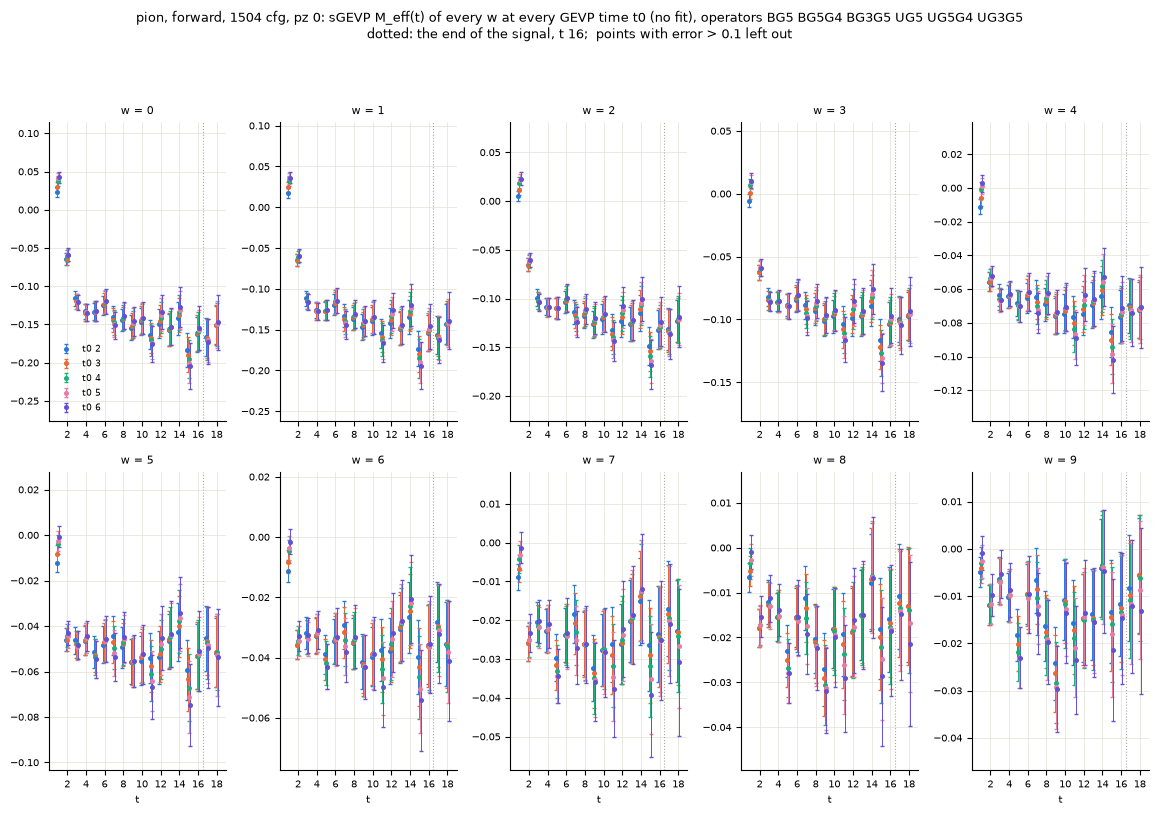

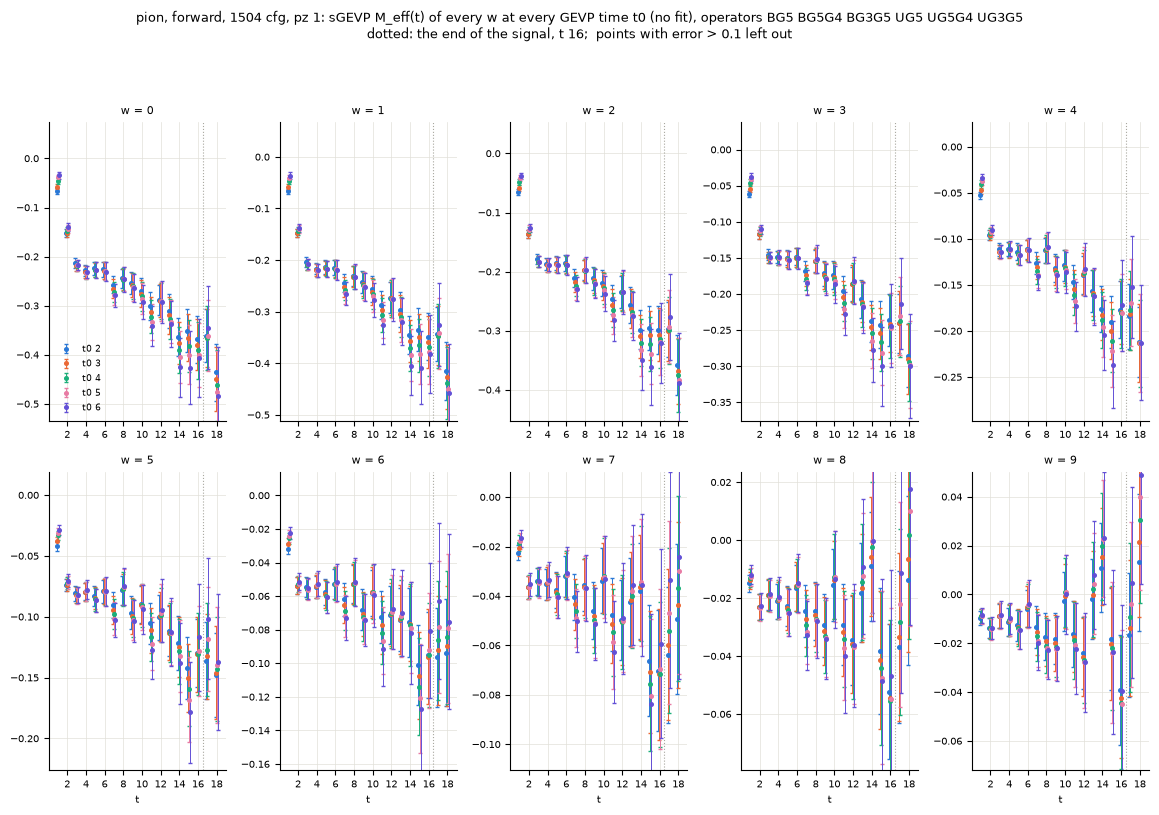

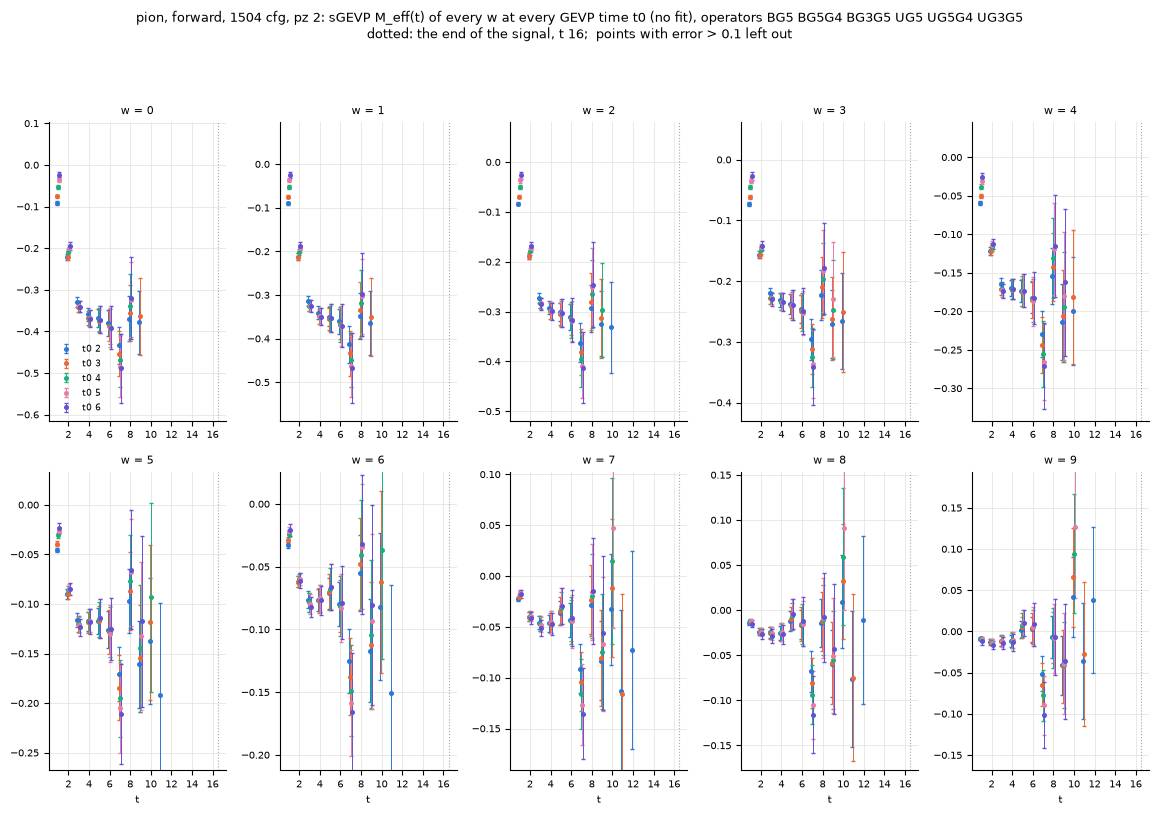

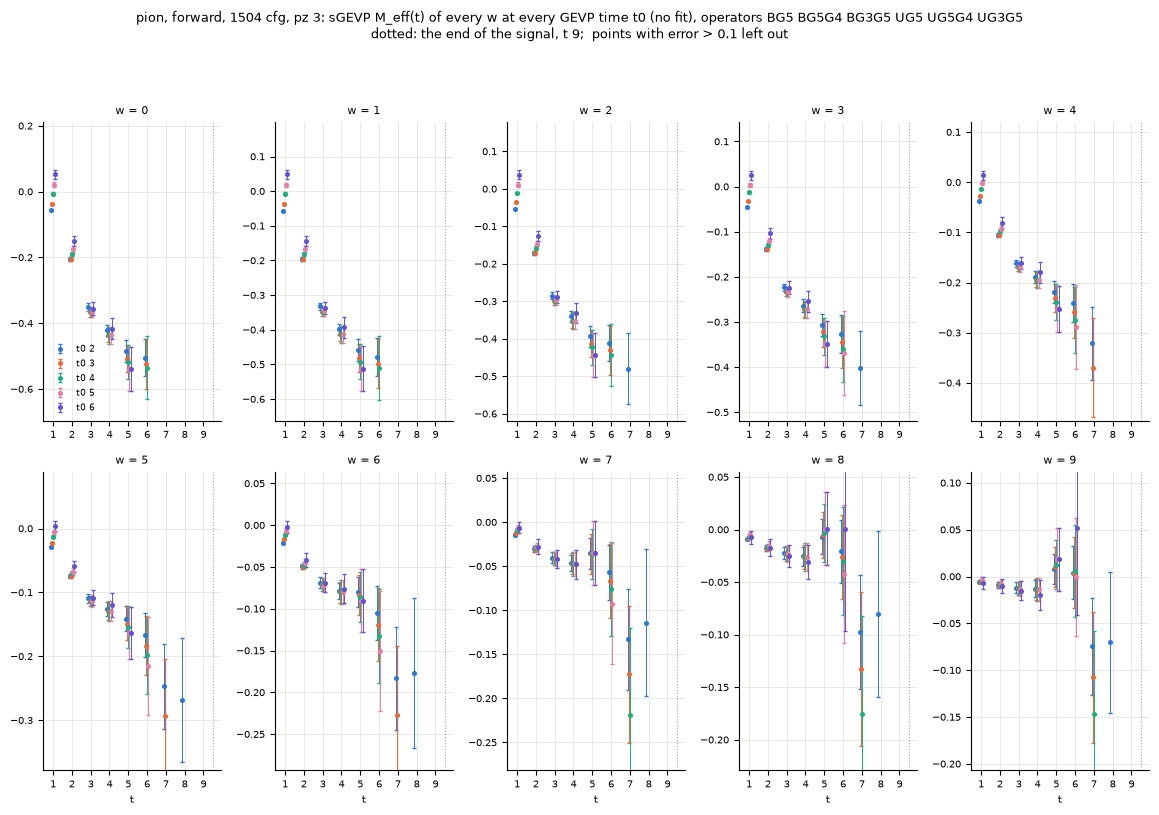

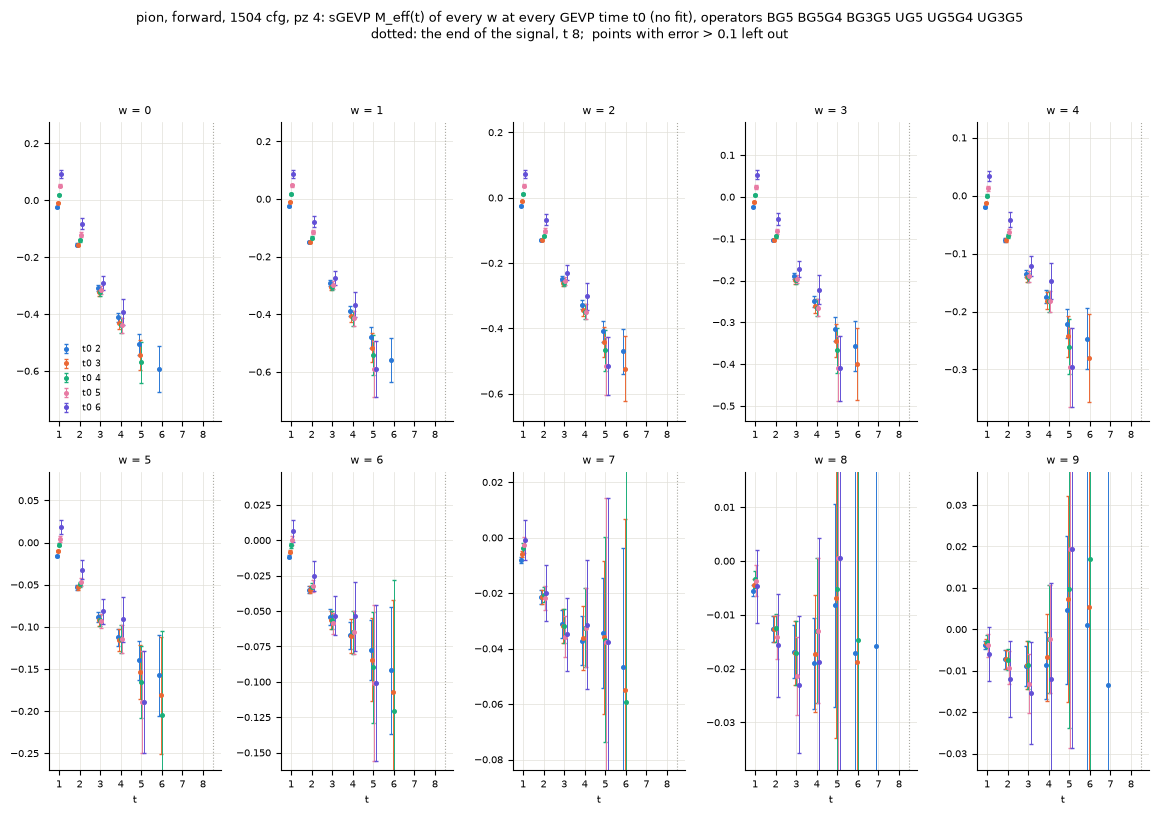

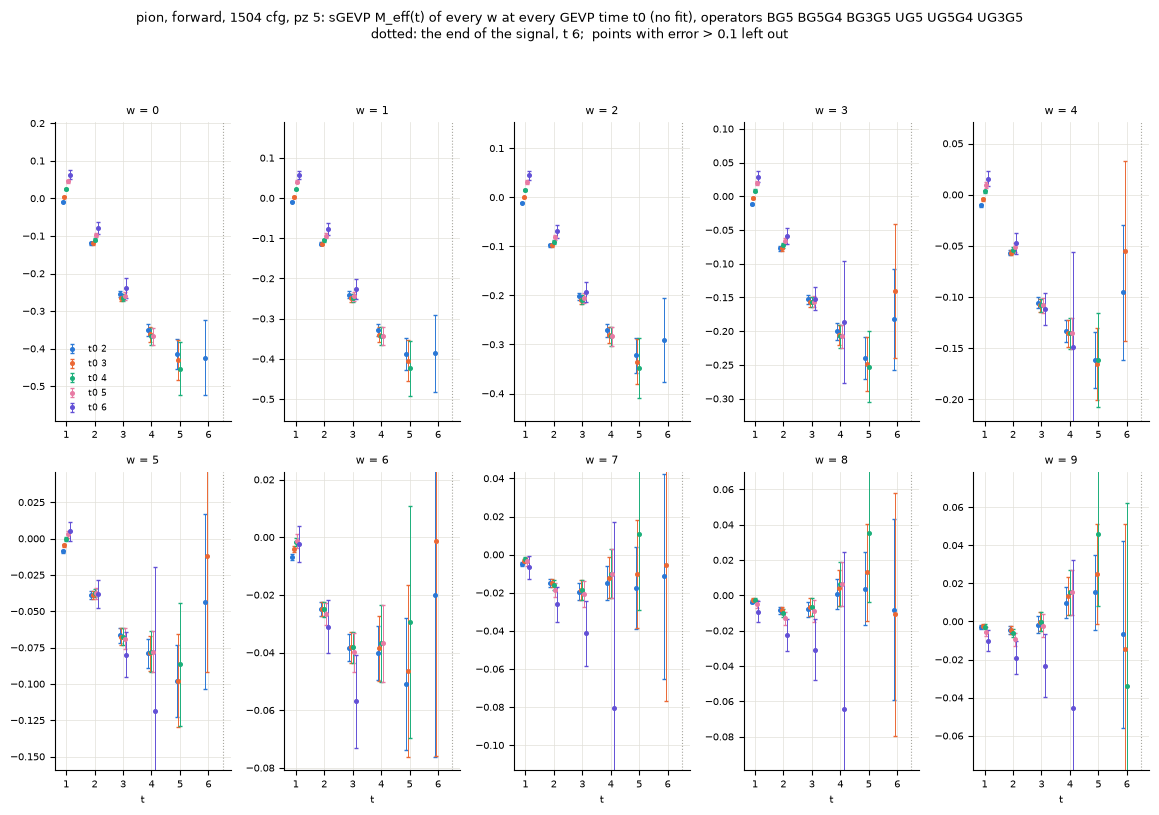

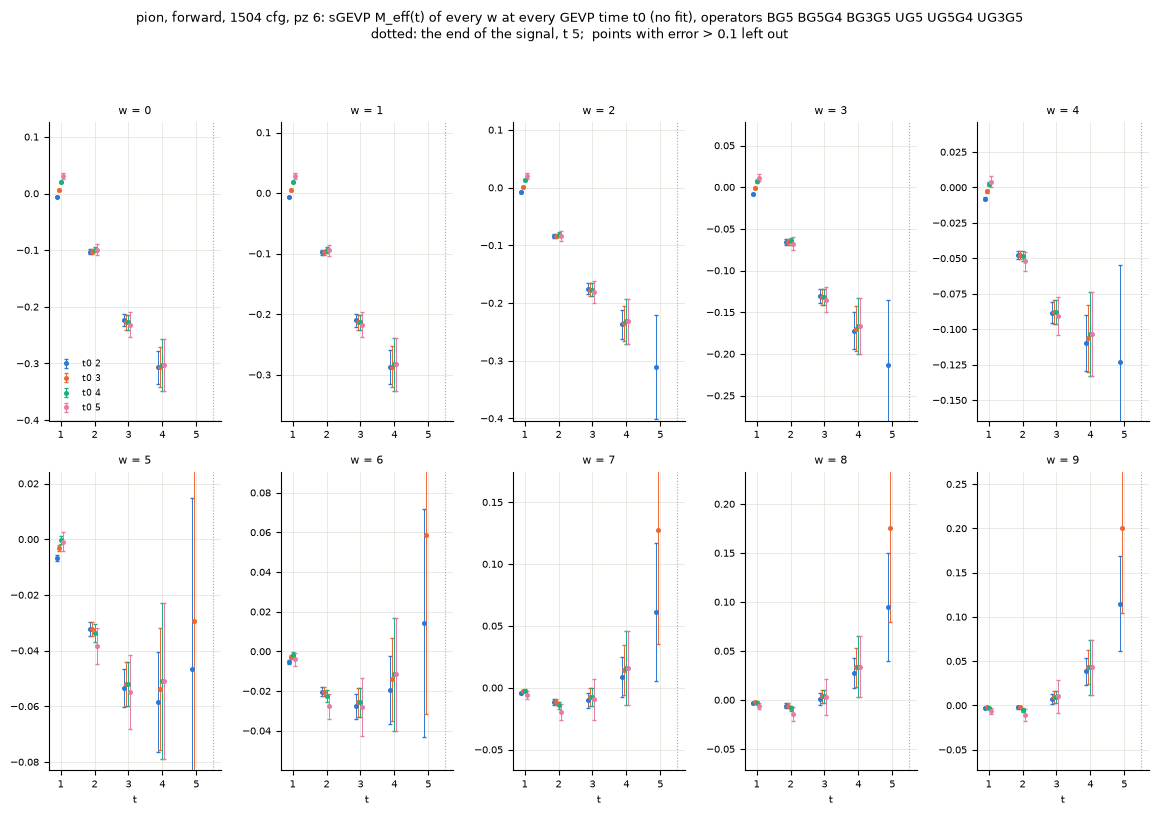

saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/1504cfg_analysis/pion_ncfg1504/plots/2_sgevp_meff_data_pion_ncfg1504.pdf and the PNGs in /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/1504cfg_analysis/pion_ncfg1504/plots/2_meff_data


In [4]:
#======== plot: the sGEVP M_eff(t) of every w, the t0 of each pz overlaid (no fit);  one page per pz, saved as PNG and in one PDF ========
#reads meff_file (section 2), so after a restart only section 0 has to be run before this cell
meff_plot_err_max = 0.1             #points with a larger error are left out
meff_plot_t_after_end = 2           #points up to the end of the signal + this (and at most t 18)
t0_colors = {2: "#2a78d6", 3: "#eb6834", 4: "#1baf7a", 5: "#e87ba4", 6: "#6250d6"}

with h5py.File(meff_file, "r") as f:
    meff_saved = {}
    for t0 in sgevp_t0_list:
        meff_saved[t0] = f[f"meff_jk_t0{t0}"][()]           #(jk, pz, w, t)
    end_saved = f["signal_end"][()]
    pz_saved = f["pz_list"][()]
    w_saved = f["w_list"][()]
os.makedirs(plot_dir, exist_ok=True)
pdf_file = os.path.join(plot_dir, f"2_sgevp_meff_data_{hadron_tag}_ncfg{ncfg}.pdf")
with PdfPages(pdf_file) as pdf:
    for ipz, pz in enumerate(pz_saved):
        t0s = sgevp_t0_of_pz[int(pz)]
        fig, axes = plt.subplots(2, 5, figsize=(11.69, 8.27))
        t_plot = np.arange(1, min(end_saved[ipz] + meff_plot_t_after_end + 1, 19))
        for iw, ax in enumerate(axes.flat):
            values = []                 #the plotted means up to the end of the signal: they set the y range
            for i, t0 in enumerate(t0s):
                m, e = jk(meff_saved[t0][:, ipz, iw][:, t_plot])
                ok = np.isfinite(m) & (e < meff_plot_err_max)
                ax.errorbar(t_plot[ok] + 0.06 * (i - 2), m[ok], e[ok], color=t0_colors[t0], marker="o", ms=2.6, ls="none", elinewidth=0.7, capsize=1.2, label=f"t0 {t0}")
                values = values + list(m[ok & (t_plot <= end_saved[ipz])])
            if len(values) > 0:
                pad = 0.25 * (max(values) - min(values)) + 0.01
                ax.set_ylim(min(values) - pad, max(values) + pad)
            ax.axvline(end_saved[ipz] + 0.5, color="#a8a79f", lw=0.8, ls=":")
            ax.grid(color="#e1e0d9", lw=0.5)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(labelsize=7)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.set_title(f"w = {w_saved[iw]}", fontsize=8)
            if iw >= 5:
                ax.set_xlabel("t", fontsize=7)
        axes.flat[0].legend(fontsize=6.5, frameon=False)
        fig.suptitle(f"{plot_title}, pz {pz}: sGEVP M_eff(t) of every w at every GEVP time t0 (no fit), operators {' '.join(sgevp_ops)}\n"
                     f"dotted: the end of the signal, t {end_saved[ipz]};  points with error > {meff_plot_err_max} left out", fontsize=9)
        fig.tight_layout(rect=(0, 0, 1, 0.94))
        save_figure(fig, pdf, "2_meff_data", f"sgevp_meff_data_pz{pz}")
print("saved", pdf_file, "and the PNGs in", os.path.join(plot_dir, "2_meff_data"))

## 4. sGEVP fits $M_{\rm eff}(t) = A_w + B_w\, t\, e^{-\Delta E\, t}$: every pz, $t_0$, svdcut and window; every fit parameter is here

In [5]:
#======== fit M_eff(t) = A_w + B_w t exp(-dE t):  every pz, t0, svdcut and window of the B1 grid;  every fit parameter is here;  every fit is saved in its own file ========
#all ten w in one fit with one dE (FIT_PLAN.md section 4);  A_w = the matrix element M(pz, w), forced negative:  A_w = -exp(a_w)
#reads meff_file (section 2), so after a restart only section 0 has to be run before this cell;  a fit whose file exists is not done again
fit_pz_run = [0, 1, 2, 3, 4, 5, 6]          #the pz to fit;  the t0 of each pz: sgevp_t0_of_pz (section 0)
fit_svdcuts = [1.0, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-12]       #every fit is made at each svdcut;  nothing is averaged over svdcuts (section 5)
#the windows (first t, last t) of each pz (FIT_PLAN.md sections 4 and 7);  t = source-sink separation, M_eff(t) = R(t+1) - R(t)
fit_window_fixed = {0: (2, 12), 1: (2, 12), 2: (2, 9), 3: (2, 8), 4: (2, 7), 5: (2, 6), 6: (2, 6)}
#the AIC windows of each pz, written out:  {pz: {first t: (smallest last t, largest last t)}};  every last t from the smallest to the largest is one window
#  B1 = the full grid: every B1 window is fitted at every t0 and svdcut;  B2 = the last t only (first t 2): it is part of B1, so it needs no fit of its own
#  These are the windows of the rule of FIT_PLAN.md section 7, with the ends of the signal of the 1504-cfg data (section 2, t0 2: pion 16 16 16 9 8 6 5,
#  proton 16 15 12 11 11 9 8):  B1 = first t 2, 3, 4 and last t from first t + 4 up to the end of the signal;  B2 = first t 2 and last t from 6 up to the end
#  of the signal;  where the end of the signal is below the last t of the fixed window, up to that last t (pion pz 6)
if hadron == "pion":
    fit_aic_B1 = {0: {2: (6, 16), 3: (7, 16), 4: (8, 16)}, # when t ranges from 2-6, we have 5*10 data points and 10+10+1 parameters
                  1: {2: (6, 16), 3: (7, 16), 4: (8, 16)},
                  2: {2: (6, 16), 3: (7, 16), 4: (8, 16)},
                  3: {2: (6, 9), 3: (7, 9), 4: (8, 9)},
                  4: {2: (6, 8), 3: (7, 8), 4: (8, 8)},
                  5: {2: (6, 6)},
                  6: {2: (6, 6)}}
    fit_aic_B2 = {0: {2: (6, 16)}, 1: {2: (6, 16)}, 2: {2: (6, 16)}, 3: {2: (6, 9)}, 4: {2: (6, 8)}, 5: {2: (6, 6)}, 6: {2: (6, 6)}}
else:
    fit_aic_B1 = {0: {2: (6, 16), 3: (7, 16), 4: (8, 16)},
                  1: {2: (6, 15), 3: (7, 15), 4: (8, 15)},
                  2: {2: (6, 12), 3: (7, 12), 4: (8, 12)},
                  3: {2: (6, 11), 3: (7, 11), 4: (8, 11)},
                  4: {2: (6, 11), 3: (7, 11), 4: (8, 11)},
                  5: {2: (6, 9), 3: (7, 9), 4: (8, 9)},
                  6: {2: (6, 8), 3: (7, 8), 4: (8, 8)}}
    fit_aic_B2 = {0: {2: (6, 16)}, 1: {2: (6, 15)}, 2: {2: (6, 12)}, 3: {2: (6, 11)}, 4: {2: (6, 11)}, 5: {2: (6, 9)}, 6: {2: (6, 8)}}
#priors:  log(-A_w) = log(-fit_A_prior[0]) ... written as -A = 1(10), i.e. log(-A) = 0(10);  B_w;  dE log-normal (the fit varies log(dE))
fit_minus_A_prior = (1.0, 10.0)             #(center, width) of -A, used as log(-A) = log(1(10)) = 0(10)
fit_B_prior = (0.0, 10.0)
fit_dE_prior = (0.5, 0.5)                   #dE prior not taken from 2pt fit
#the fit of the jackknife mean keeps the lowest chi2 of six starts:
#  starts 1-5: dE from fit_dE_starts, -A = -M_eff at the last t (at least fit_minus_A_min), B from the first point;
#  start 6: the same fit with A sign free (prior fit_free_A_prior on A) from the five starts, the lowest chi2 kept, then every A above -fit_minus_A_min set to -fit_minus_A_min
#every jackknife sample starts from the fit of the mean
fit_dE_starts = [0.15, 0.3, 0.5, 0.8, 1.2]
fit_free_A_prior = (0.0, 10.0)
fit_minus_A_min = 1e-3
fit_maxit = 20000
fit_tol = 1e-8
fit_fitter = "scipy_least_squares"
#fixed:  the covariance of the fit of the mean is the jackknife covariance of all cfgs;  jackknife sample j is fitted with the covariance of the other cfgs (rebuilt without cfg j);
#        all t of the window and all w are correlated (full covariance)
fit_settings = (f"A < 0, -A {fit_minus_A_prior}, B {fit_B_prior}, dE {fit_dE_prior}, starts {fit_dE_starts} + sign-free start A {fit_free_A_prior}, -A at least {fit_minus_A_min}, "
                f"maxit {fit_maxit}, tol {fit_tol}, {fit_fitter}, covariance per sample")

if not gv.BufferDict.has_distribution("neglog"):       #a name for gvar, like its own "log":  the fit varies neglog(A), and p["A"] = -exp(neglog(A))
    gv.BufferDict.add_distribution("neglog", lambda x: -gv.exp(x))


def sgevp_fit_path(pz, t0, svdcut, window):
    #the file of one fit
    return os.path.join(sgevp_fit_dir, f"t0{t0}", f"sgevp_fit_six_t0{t0}_pz{pz}_svd{svdcut:g}_t{window[0]}-{window[1]}_{hadron_tag}.npz")


def fit_meff_jackknife(y_jk, t_points, svdcut, out_file):
    #one sGEVP fit in every jackknife sample;  y_jk (jk, w, n_t): M_eff of all w at the times t_points;  saves out_file and returns one line of text
    if not gv.BufferDict.has_distribution("neglog"):   #every worker process needs it too
        gv.BufferDict.add_distribution("neglog", lambda x: -gv.exp(x))
    time_fit = time.time()
    n_jk, n_w_fit, n_t = y_jk.shape
    t = t_points.astype(float)
    x = {"t": np.tile(t, n_w_fit), "iw": np.repeat(np.arange(n_w_fit), n_t)}      #every point: its t and its w index, w after w

    def model(x, p):
        return p["A"][x["iw"]] + p["B"][x["iw"]] * x["t"] * gv.exp(-p["dE"][0] * x["t"])

    def prior():
        #A < 0;  made again after every gv.switch_gvar()
        p = gv.BufferDict()
        p["neglog(A)"] = gv.log(gv.gvar(np.full(n_w_fit, fit_minus_A_prior[0]), np.full(n_w_fit, fit_minus_A_prior[1])))
        p["B"] = gv.gvar(np.full(n_w_fit, fit_B_prior[0]), np.full(n_w_fit, fit_B_prior[1]))
        p["log(dE)"] = gv.log(gv.gvar([float(fit_dE_prior[0])], [float(fit_dE_prior[1])]))
        return p

    def prior_free():
        #A sign free:  only for the sixth start
        p = gv.BufferDict()
        p["A"] = gv.gvar(np.full(n_w_fit, fit_free_A_prior[0]), np.full(n_w_fit, fit_free_A_prior[1]))
        p["B"] = gv.gvar(np.full(n_w_fit, fit_B_prior[0]), np.full(n_w_fit, fit_B_prior[1]))
        p["log(dE)"] = gv.log(gv.gvar([float(fit_dE_prior[0])], [float(fit_dE_prior[1])]))
        return p

    Y = y_jk.reshape(n_jk, n_w_fit * n_t)                  #(jk, point)
    y_mean = Y.mean(axis=0)
    D = Y - y_mean
    cov_all = (n_jk - 1) / n_jk * (D.T @ D)                 #jackknife covariance of the mean, all cfgs
    y_mean_w = y_mean.reshape(n_w_fit, n_t)
    #---- the fit of the jackknife mean:  starts 1-5
    starts = []
    for dE_start in fit_dE_starts:
        starts.append({"neglog(A)": np.log(np.maximum(-y_mean_w[:, -1], fit_minus_A_min)),
                       "B": (y_mean_w[:, 0] - y_mean_w[:, -1]) / (t[0] * np.exp(-dE_start * t[0])),
                       "log(dE)": np.log([dE_start])})
    #start 6: the sign-free fit from the five starts, lowest chi2, every A above -fit_minus_A_min set to -fit_minus_A_min
    free = None
    chi2_free = np.nan
    n_free = 0
    for p0 in starts:
        gv.switch_gvar()
        fit = lsqfit.nonlinear_fit(data=(x, gv.gvar(y_mean, cov_all)), fcn=model, prior=prior_free(), p0={"A": y_mean_w[:, -1], "B": p0["B"], "log(dE)": p0["log(dE)"]},
                                   svdcut=svdcut, maxit=fit_maxit, tol=fit_tol, fitter=fit_fitter)
        n_free = n_free + 1
        if free is None or fit.chi2 < chi2_free:
            chi2_free = float(fit.chi2)
            free = {"A": np.array(fit.pmean["A"]), "B": np.array(fit.pmean["B"]), "log(dE)": np.array(fit.pmean["log(dE)"])}
        gv.restore_gvar()
    starts.append({"neglog(A)": np.log(np.maximum(-free["A"], fit_minus_A_min)), "B": free["B"], "log(dE)": free["log(dE)"]})
    #the forced-sign fit from each of the six starts:  the lowest chi2 is kept
    best = None
    chi2_starts = []
    for p0 in starts:
        gv.switch_gvar()
        fit = lsqfit.nonlinear_fit(data=(x, gv.gvar(y_mean, cov_all)), fcn=model, prior=prior(), p0=p0, svdcut=svdcut, maxit=fit_maxit, tol=fit_tol, fitter=fit_fitter)
        chi2_starts.append(float(fit.chi2))
        if best is None or fit.chi2 < best["chi2"]:
            best = {"chi2": float(fit.chi2), "dof": int(fit.dof), "svdn": int(fit.svdn), "bad": int(fit.stopping_criterion == 0),
                    "p0": {"neglog(A)": np.array(fit.pmean["neglog(A)"]), "B": np.array(fit.pmean["B"]), "log(dE)": np.array(fit.pmean["log(dE)"])}}
        gv.restore_gvar()
    #---- every jackknife sample, with the covariance of the other cfgs:  the per-cfg values are made back from the samples,
    #     and cfg j is taken out of their sum of squares (the same as np.cov of the other cfgs, / (number of cfgs - 1))
    y_cfg = n_jk * y_mean - (n_jk - 1) * Y                  #(cfg, point)
    y_c = y_cfg - y_cfg.mean(axis=0)
    Q = y_c.T @ y_c
    m = n_jk - 1
    A_jk = np.zeros((n_jk, n_w_fit))
    B_jk = np.zeros((n_jk, n_w_fit))
    dE_jk = np.zeros((n_jk, 1))
    chi2_jk = np.zeros(n_jk)
    n_bad = best["bad"]
    for j in range(n_jk):
        cov_j = (Q - (1 + 1 / m) * np.outer(y_c[j], y_c[j])) / (m - 1) / (n_jk - 1)
        gv.switch_gvar()
        fit = lsqfit.nonlinear_fit(data=(x, gv.gvar(Y[j], cov_j)), fcn=model, prior=prior(), p0=best["p0"], svdcut=svdcut, maxit=fit_maxit, tol=fit_tol, fitter=fit_fitter)
        A_jk[j] = fit.pmean["A"]
        B_jk[j] = fit.pmean["B"]
        dE_jk[j] = fit.pmean["dE"]
        chi2_jk[j] = fit.chi2
        n_bad = n_bad + int(fit.stopping_criterion == 0)
        gv.restore_gvar()
    #---- pulls:  (data mean - mean over the samples of the model curve) / jackknife error of the point
    y_m, y_e = jk(y_jk)                                     #(w, n_t)
    curve = np.zeros((n_w_fit, n_t))
    for iw in range(n_w_fit):
        curve[iw] = (A_jk[:, iw, None] + B_jk[:, iw, None] * t * np.exp(-dE_jk[:, 0, None] * t)).mean(axis=0)
    np.savez(out_file, window=np.array([t_points[0], t_points[-1]]), A=A_jk, B=B_jk, dE=dE_jk, M_jk=A_jk, dE_jk=dE_jk[:, 0], chi2_jk=chi2_jk, chi2=best["chi2"], dof=best["dof"],
             svdn=best["svdn"], n_bad=n_bad, n_fit=n_jk + len(starts) + n_free, chi2_starts=np.array(chi2_starts), chi2_free=chi2_free, y_mean=y_m, y_err=y_e,
             curve_mean=curve, pull=(y_m - curve) / y_e, k=2 * n_w_fit + 1, n_point=n_w_fit * n_t, svdcut=svdcut, n_jk=n_jk, x_t=t, settings=fit_settings)
    return f"{os.path.basename(out_file)}: chi2/dof {best['chi2'] / best['dof']:.3f}, {n_bad} fits at maxit, {time.time() - time_fit:.0f} s"


#---- the M_eff of section 2, and the windows of each pz
with h5py.File(meff_file, "r") as f:
    meff_saved = {}
    for t0 in sgevp_t0_list:
        meff_saved[t0] = f[f"meff_jk_t0{t0}"][()]           #(jk, pz, w, t)
    end_saved = f["signal_end"][()]
    pz_saved = list(f["pz_list"][()])
fit_windows = {}        #fit_windows[pz]: {"fixed": [(first, last)], "B1": [...], "B2": [...]}
for pz in fit_pz_run:
    ipz = pz_saved.index(pz)
    fit_windows[pz] = {"fixed": [fit_window_fixed[pz]], "B1": [], "B2": []}
    for first in fit_aic_B1[pz]:
        for last in range(fit_aic_B1[pz][first][0], fit_aic_B1[pz][first][1] + 1):
            fit_windows[pz]["B1"].append((first, last))
    for first in fit_aic_B2[pz]:
        for last in range(fit_aic_B2[pz][first][0], fit_aic_B2[pz][first][1] + 1):
            fit_windows[pz]["B2"].append((first, last))
    assert fit_window_fixed[pz] in fit_windows[pz]["B1"] and set(fit_windows[pz]["B2"]) <= set(fit_windows[pz]["B1"]), f"pz {pz}: the fixed window and the B2 grid have to be part of the B1 grid"
    print(f"pz {pz}: end of the signal {end_saved[ipz]} (section 2);  fixed {fit_window_fixed[pz][0]}-{fit_window_fixed[pz][1]};  B1 {len(fit_windows[pz]['B1'])} windows (largest last t {max(w[1] for w in fit_windows[pz]['B1'])});  "
          f"B2 {len(fit_windows[pz]['B2'])} windows (last t {fit_windows[pz]['B2'][0][1]}-{fit_windows[pz]['B2'][-1][1]});  t0 {' '.join(str(t0) for t0 in sgevp_t0_of_pz[pz])}")

#---- every fit that is not saved yet:  the longest windows first, so that the workers finish at about the same time
fit_tasks = []          #(pz, t0, svdcut, window)
n_all = 0
for pz in fit_pz_run:
    for t0 in sgevp_t0_of_pz[pz]:
        os.makedirs(os.path.join(sgevp_fit_dir, f"t0{t0}"), exist_ok=True)
        for svdcut in fit_svdcuts:
            for window in fit_windows[pz]["B1"]:
                n_all = n_all + 1
                if not os.path.exists(sgevp_fit_path(pz, t0, svdcut, window)):
                    fit_tasks.append((pz, t0, svdcut, window))
fit_tasks.sort(key=lambda task: -(task[3][1] - task[3][0]))
print(f"{n_all} fits in all, {n_all - len(fit_tasks)} already saved, {len(fit_tasks)} to do with {n_workers} workers (about {len(fit_tasks) * 13 / max(n_workers, 1) / 3600:.1f} h)", flush=True)
time_start = time.time()
lines = Parallel(n_jobs=n_workers, verbose=5)(delayed(fit_meff_jackknife)(meff_saved[t0][:, pz_saved.index(pz)][:, :, np.arange(window[0], window[1] + 1)],
                                                                           np.arange(window[0], window[1] + 1), svdcut, sgevp_fit_path(pz, t0, svdcut, window))
                                              for pz, t0, svdcut, window in fit_tasks)
print(f"done, {time.time() - time_start:.0f} s")

#---- check every fit:  how many stopped at maxit
for pz in fit_pz_run:
    n_bad = 0
    n_fits = 0
    for t0 in sgevp_t0_of_pz[pz]:
        for svdcut in fit_svdcuts:
            for window in fit_windows[pz]["B1"]:
                d = np.load(sgevp_fit_path(pz, t0, svdcut, window))
                n_bad = n_bad + int(d["n_bad"])
                n_fits = n_fits + int(d["n_fit"])
    print(f"pz {pz}: {len(sgevp_t0_of_pz[pz]) * len(fit_svdcuts) * len(fit_windows[pz]['B1'])} jackknife fits, {n_fits} single fits, {n_bad} stopped at maxit")

pz 0: end of the signal 16 (section 2);  fixed 2-12;  B1 30 windows (largest last t 16);  B2 11 windows (last t 6-16);  t0 2 3 4 5 6
pz 1: end of the signal 16 (section 2);  fixed 2-12;  B1 30 windows (largest last t 16);  B2 11 windows (last t 6-16);  t0 2 3 4 5 6
pz 2: end of the signal 16 (section 2);  fixed 2-9;  B1 30 windows (largest last t 16);  B2 11 windows (last t 6-16);  t0 2 3 4 5 6
pz 3: end of the signal 9 (section 2);  fixed 2-8;  B1 9 windows (largest last t 9);  B2 4 windows (last t 6-9);  t0 2 3 4 5 6
pz 4: end of the signal 8 (section 2);  fixed 2-7;  B1 6 windows (largest last t 8);  B2 3 windows (last t 6-8);  t0 2 3 4 5 6
pz 5: end of the signal 6 (section 2);  fixed 2-6;  B1 1 windows (largest last t 6);  B2 1 windows (last t 6-6);  t0 2 3 4 5 6
pz 6: end of the signal 5 (section 2);  fixed 2-6;  B1 1 windows (largest last t 6);  B2 1 windows (last t 6-6);  t0 2 3 4 5
5340 fits in all, 0 already saved, 5340 to do with 13 workers (about 1.5 h)


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.
[Parallel(n_jobs=13)]: Done  46 tasks      | elapsed:  1.2min
[Parallel(n_jobs=13)]: Done 136 tasks      | elapsed:  3.5min
[Parallel(n_jobs=13)]: Done 262 tasks      | elapsed:  6.6min


KeyboardInterrupt: 

## 5. AIC over the windows and average over $t_0$ at every svdcut; double and single ratio

In [ ]:
#======== window AIC and the average over t0 (FIT_PLAN.md section 11), in every jackknife sample, at every svdcut;  then the double and single ratio (section 5);  saved ========
#variants:  "fixed" = the fixed window of each pz at every t0;  "B1" = every window of the B1 grid at every t0;  "B2" = every window of the B2 grid at every t0
#weight of a (t0, window) in jackknife sample j:  w ~ exp[-(chi2_j + 2k + 2 N_cut)/2],  chi2_j of that sample's fit (priors included),  k = 21 fit parameters,
#  N_cut = 10 w x the t of the union of the variant's windows that this window leaves out;  normalized over all (t0, window) of the variant
#  this is the window AIC at each t0 followed by the average over t0;  with one window per t0 ("fixed") it is exp(-chi2_j/2) over t0 (FIT_PLAN.md section 9, D2)
#M(pz, w) and dE of sample j = the weighted averages over the (t0, window);  nothing is averaged over svdcuts (chi2 at different svdcuts cannot be compared)
#double ratio D(pz, w) = [M(pz, w) / M(pz, 0)] / [M(0, w) / M(0, 0)]
#single ratio S(pz, w) = M(pz, w) / M(0, w) x E0(0) / E0(pz),  E0 of the same jackknife sample from the 2pt AIC of the projected 2pt (section 3 of matrix_element_analysis_1504cfg_2pt.ipynb)
#reads the fit files of section 4 and pt2_result_file (made by matrix_element_analysis_1504cfg_2pt.ipynb);  after a restart run sections 0 and 4 first (section 4 then fits nothing again)
variants = ["fixed", "B1", "B2"]
print_svdcut = 1e-2         #the svdcut of the tables printed below (every svdcut is saved)
time_start = time.time()

assert os.path.exists(pt2_result_file), f"no E0 file {pt2_result_file}:  run matrix_element_analysis_1504cfg_2pt.ipynb (sections 0 and 3) first, with the same hadron"
with h5py.File(pt2_result_file, "r") as f:
    E0_jk = f["projected/E0_jk"][()]            #(jk, pz)
    assert list(f["pz_list"][()]) == pz_saved, "the 2pt fit has other pz than the sGEVP"
n_jk = E0_jk.shape[0]
n_w = meff_saved[sgevp_t0_list[0]].shape[2]
assert fit_pz_run == list(range(len(pz_saved))), "the ratios need every pz:  fit_pz_run = [0, 1, ..., 6]"

result = {}             #result[(svdcut, variant)]: M (jk, w, pz), dE (jk, pz), D (jk, w, pz), S (jk, w, pz)
choice_info = {}        #choice_info[(svdcut, variant, pz)]: the (t0, window) of the average, their weights, and M(w 0), M(w 4)/M(w 0) of each
for svdcut in fit_svdcuts:
    for variant in variants:
        M = np.zeros((n_jk, n_w, len(pz_saved)))
        dE = np.zeros((n_jk, len(pz_saved)))
        for pz in fit_pz_run:
            choices = []        #(t0, first t, last t)
            for t0 in sgevp_t0_of_pz[pz]:
                for window in fit_windows[pz][variant]:
                    choices.append((t0, window[0], window[1]))
            #the t of the union of the windows of this variant (the same at every t0)
            union = set()
            for window in fit_windows[pz][variant]:
                union = union | set(range(window[0], window[1] + 1))
            chi2_jk = np.zeros((n_jk, len(choices)))            #(jk, choice)
            M_choice = np.zeros((n_jk, len(choices), n_w))      #(jk, choice, w)
            dE_choice = np.zeros((n_jk, len(choices)))          #(jk, choice)
            k = np.zeros(len(choices))                          #number of fit parameters of each choice
            n_cut = np.zeros(len(choices))                      #N_cut of each choice
            for i, (t0, first, last) in enumerate(choices):
                d = np.load(sgevp_fit_path(pz, t0, svdcut, (first, last)))
                if "settings" in d.files:                       #fits made before this notebook have no settings text
                    assert str(d["settings"]) == fit_settings, f"{sgevp_fit_path(pz, t0, svdcut, (first, last))} was made with other fit settings: delete it and fit again (section 4)"
                chi2_jk[:, i] = d["chi2_jk"]
                M_choice[:, i] = d["M_jk"]
                dE_choice[:, i] = d["dE_jk"]
                k[i] = int(d["k"])
                n_cut[i] = n_w * (len(union) - (last - first + 1))
            aic = chi2_jk + 2 * k + 2 * n_cut                               #(jk, choice)
            weight = np.exp(-0.5 * (aic - aic.min(axis=1, keepdims=True)))
            weight = weight / weight.sum(axis=1, keepdims=True)
            M[:, :, pz] = (weight[:, :, None] * M_choice).sum(axis=1)
            dE[:, pz] = (weight * dE_choice).sum(axis=1)
            choice_info[(svdcut, variant, pz)] = {"choices": np.array(choices), "weight_jk": weight, "weight_mean": weight.mean(axis=0), "weight_sd": weight.std(axis=0),
                                                  "M0": jk(M_choice[:, :, 0]), "R4": jk(M_choice[:, :, 4] / M_choice[:, :, 0]),
                                                  "best": choices[int(np.argmax(weight.mean(axis=0)))]}
        D = (M / M[:, :1]) / (M[:, :, :1] / M[:, :1, :1])                  #(jk, w, pz)
        S = M / M[:, :, :1] * (E0_jk[:, None, :1] / E0_jk[:, None, :])      #(jk, w, pz)
        result[(svdcut, variant)] = {"M": M, "dE": dE, "D": D, "S": S}
print(f"read {len(fit_svdcuts)} svdcuts x {len(variants)} variants, {time.time() - time_start:.0f} s")

#---- save
os.makedirs(os.path.dirname(sgevp_result_file), exist_ok=True)
if os.path.exists(sgevp_result_file):
    print("replacing", sgevp_result_file)
with h5py.File(sgevp_result_file, "w") as f:
    for (svdcut, variant), res in result.items():
        group = f"svd{svdcut:g}/{variant}"
        f[f"{group}/M_jk"] = res["M"]               #(jk, w, pz)
        f[f"{group}/dE_jk"] = res["dE"]             #(jk, pz)
        f[f"{group}/D_jk"] = res["D"]               #(jk, w, pz): double ratio
        f[f"{group}/S_jk"] = res["S"]               #(jk, w, pz): single ratio
        for pz in fit_pz_run:
            info = choice_info[(svdcut, variant, pz)]
            f[f"{group}/pz{pz}/choices"] = info["choices"]          #(choice, 3): t0, first t, last t
            f[f"{group}/pz{pz}/weight_jk"] = info["weight_jk"]      #(jk, choice)
    f["E0_jk"] = E0_jk                              #(jk, pz):  the E0 of S
    f["svdcuts"] = fit_svdcuts
    f["variants"] = variants
    f["pz_list"] = pz_saved
    f["w_list"] = np.arange(n_w)
    f["fit_settings"] = fit_settings
    f["t0_of_pz"] = [" ".join(str(t0) for t0 in sgevp_t0_of_pz[pz]) for pz in fit_pz_run]
    f["window_fixed"] = [fit_window_fixed[pz] for pz in fit_pz_run]
    f["pt2_result_file"] = pt2_result_file
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
print("saved", sgevp_result_file)

#---- print at print_svdcut:  D(w 4), D(w 8), S(w 0) of the three variants, and the error of B1 and B2 divided by the error of the fixed windows
print(f"{plot_title}, svdcut {print_svdcut:g}, t0 average;  pz 1-{len(pz_saved) - 1}")
for kind, w in (("D", 4), ("D", 8), ("S", 0)):
    for variant in variants:
        mean, err = jk(result[(print_svdcut, variant)][kind][:, w, 1:])
        print(f"{kind}(w {w}) {variant:>5s}: " + " ".join(f"{str(gv.gvar(mean[i], err[i])):>11s}" for i in range(len(mean))))
    for variant in ["B1", "B2"]:
        ratio = jk(result[(print_svdcut, variant)][kind][:, w, 1:])[1] / jk(result[(print_svdcut, "fixed")][kind][:, w, 1:])[1]
        print(f"   error {variant} / fixed: " + " ".join(f"{r:11.2f}" for r in ratio))
print("largest-weight (t0, first t, last t) of each pz:")
for variant in ["B1", "B2"]:
    print(f"{variant}: " + ";  ".join(f"pz {pz} {choice_info[(print_svdcut, variant, pz)]['best']} ({choice_info[(print_svdcut, variant, pz)]['weight_mean'].max():.2f})" for pz in fit_pz_run))

## 6a. Plots: the fitted $M_{\rm eff}$ at svdcut 1e-2 (fixed window at every $t_0$, largest-weight B1 and B2)

In [ ]:
#======== plots:  the fitted M_eff at one svdcut:  the fixed window at every t0, and the largest-weight (t0, window) of B1 and of B2;  one page per fit ========
#points: M_eff of the window (mean and jackknife error);  blue band: A + B t exp(-dE t) made in every jackknife sample, then mean and jackknife error;  grey band: M = A
#mean pull and rms pull of each w:  (data mean - mean over the samples of the curve) / error of the point, over the window
#reads the fit files of section 4 and uses the weights of section 5
sheet_svdcut = 1e-2

os.makedirs(plot_dir, exist_ok=True)
pdf_file = os.path.join(plot_dir, f"6a_sgevp_fitted_meff_svd{sheet_svdcut:g}_{hadron_tag}_ncfg{ncfg}.pdf")
with PdfPages(pdf_file) as pdf:
    for pz in fit_pz_run:
        #the pages of this pz:  (t0, window, title, PNG name)
        pages = []
        t0s = sgevp_t0_of_pz[pz]
        for i, t0 in enumerate(t0s):
            window = fit_window_fixed[pz]
            weight = choice_info[(sheet_svdcut, "fixed", pz)]["weight_mean"][i]
            pages.append((t0, window, f"fixed window {window[0]}-{window[1]}, t0 {t0} (t0 weight of the fixed-window average {weight:.2f})", f"sheet_pz{pz}_fixed_t0{t0}"))
        for variant in ["B1", "B2"]:
            t0, first, last = choice_info[(sheet_svdcut, variant, pz)]["best"]
            weight = choice_info[(sheet_svdcut, variant, pz)]["weight_mean"].max()
            pages.append((t0, (first, last), f"{variant}: largest weight t0 {t0}, window {first}-{last} (weight {weight:.2f})", f"sheet_pz{pz}_{variant}"))
        for t0, window, title, png_name in pages:
            d = np.load(sgevp_fit_path(pz, t0, sheet_svdcut, window))
            t = d["x_t"]
            t_band = np.linspace(t[0] - 0.25, t[-1] + 0.25, 60)
            fig, axes = plt.subplots(2, 5, figsize=(11.69, 8.27))
            for iw, ax in enumerate(axes.flat):
                M_mean, M_err = jk(d["M_jk"][:, iw])
                ax.axhspan(M_mean - M_err, M_mean + M_err, color="#e7e7e5", lw=0, zorder=0)
                band = d["A"][:, iw, None] + d["B"][:, iw, None] * t_band * np.exp(-d["dE"][:, 0, None] * t_band)      #(jk, t)
                band_mean, band_err = jk(band)
                ax.fill_between(t_band, band_mean - band_err, band_mean + band_err, color="#2a78d6", alpha=0.25, lw=0)
                ax.errorbar(t, d["y_mean"][iw], d["y_err"][iw], color="#2a78d6", marker="o", ms=3, ls="none", elinewidth=0.8, capsize=1.5)
                pull = d["pull"][iw]
                ax.set_title(f"w = {iw}:  M = {gv.gvar(M_mean, M_err)}\nmean pull {pull.mean():+.2f}, rms {np.sqrt((pull ** 2).mean()):.2f}", fontsize=7.5)
                ax.grid(color="#e1e0d9", lw=0.5)
                ax.set_axisbelow(True)
                ax.spines[["top", "right"]].set_visible(False)
                ax.tick_params(labelsize=7)
                ax.xaxis.set_major_locator(MaxNLocator(integer=True))
                if iw >= 5:
                    ax.set_xlabel("t", fontsize=7)
            dE_mean, dE_err = jk(d["dE_jk"])
            fig.suptitle(f"{plot_title}, pz {pz}, svdcut {sheet_svdcut:g}: {title}\n"
                         f"dE = {gv.gvar(dE_mean, dE_err)};  chi2/dof {float(d['chi2']) / int(d['dof']):.3f} ({int(d['dof'])} dof);  svd modes raised {int(d['svdn'])};  "
                         f"fits at maxit {int(d['n_bad'])} of {int(d['n_fit'])};  grey band: M", fontsize=8.5)
            fig.tight_layout(rect=(0, 0.02, 1, 0.92))
            save_figure(fig, pdf, "6a_fitted_meff", png_name)
print("saved", pdf_file, "and the PNGs in", os.path.join(plot_dir, "6a_fitted_meff"))

## 6b. Plots: single and double ratio at every svdcut

In [ ]:
#======== plots:  the double ratio D and the single ratio S against nu, all pz together;  fixed, B1, B2;  one page per svdcut ========
#D: reference pz 0;  S: each jackknife sample with its own E0 of the 2pt AIC;  both with the t0 average of section 5
itd_plot_err_max = 0.5              #points with a larger error are left out
itd_ylim = {"D": (-0.3, 1.4), "S": (-0.1, 1.4)}
pz_colors = ["#52514e", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
pz_markers = ["o", "s", "^", "D", "v", "P", "X"]

os.makedirs(plot_dir, exist_ok=True)
pdf_file = os.path.join(plot_dir, f"6b_single_double_ratio_every_svdcut_{hadron_tag}_ncfg{ncfg}.pdf")
with PdfPages(pdf_file) as pdf:
    for svdcut in fit_svdcuts:
        fig, axes = plt.subplots(2, len(variants), figsize=(11.69, 8.27), sharex=True, sharey="row", squeeze=False)
        for c, variant in enumerate(variants):
            for r, kind in enumerate(["D", "S"]):
                ax = axes[r, c]
                mean, err = jk(result[(svdcut, variant)][kind])         #(w, pz)
                for pz in fit_pz_run:
                    if pz == 0:
                        continue                                        #pz 0 sits at nu = 0
                    nu = 2 * np.pi / Ls * np.arange(n_w) * pz
                    ok = err[:, pz] < itd_plot_err_max
                    ax.errorbar(nu[ok] + 0.02 * (pz - 3.5), mean[ok, pz], err[ok, pz], color=pz_colors[pz], marker=pz_markers[pz], ms=3, ls="none", elinewidth=0.8, capsize=1.5, label=f"pz = {pz}")
                ax.axhline(1, color="#898781", lw=0.6)
                ax.grid(color="#e1e0d9", lw=0.5)
                ax.set_axisbelow(True)
                ax.spines[["top", "right"]].set_visible(False)
                ax.tick_params(labelsize=7)
                ax.set_ylim(*itd_ylim[kind])
                if kind == "D":
                    ax.set_title(f"double ratio D, {variant}", fontsize=9)
                else:
                    ax.set_title(f"single ratio S, {variant}", fontsize=9)
                    ax.set_xlabel(r"$\nu = 2\pi p_z w / L_s$", fontsize=8)
        axes[0, 0].legend(fontsize=7, frameon=False, ncol=2)
        fig.suptitle(f"{plot_title}, svdcut {svdcut:g}: double ratio D (reference pz 0) and single ratio S (each sample its own E0 from the 2pt AIC)\n"
                     f"with the t0 average;  {', '.join(variants)};  points with error > {itd_plot_err_max} left out", fontsize=9.5)
        fig.tight_layout(rect=(0, 0, 1, 0.94))
        save_figure(fig, pdf, "6b_ratios", f"itd_svd{svdcut:g}")
print("saved", pdf_file, "and the PNGs in", os.path.join(plot_dir, "6b_ratios"))

## 6c. Plots: AIC weights at every svdcut

In [ ]:
#======== plots:  the AIC weight of every (t0, window), B1 and B2, every pz;  one page per svdcut and variant ========
#top: the weight (mean over the samples, bar: their sd), color = t0, the windows in grid order within each t0
#middle and bottom: M(w 0) and M(w 4)/M(w 0) of each (t0, window), dot size = weight;  band = the AIC result;  y range: 5-95 % of the choices
t0_colors = {2: "#2a78d6", 3: "#eb6834", 4: "#1baf7a", 5: "#e87ba4", 6: "#6250d6"}
variant_colors = {"fixed": "#52514e", "B1": "#2a78d6", "B2": "#eb6834"}

os.makedirs(plot_dir, exist_ok=True)
pdf_file = os.path.join(plot_dir, f"6c_aic_weights_every_svdcut_{hadron_tag}_ncfg{ncfg}.pdf")
with PdfPages(pdf_file) as pdf:
    for svdcut in fit_svdcuts:
        for variant in ["B1", "B2"]:
            fig, axes = plt.subplots(3, len(fit_pz_run), figsize=(11.69, 8.27))
            for c, pz in enumerate(fit_pz_run):
                info = choice_info[(svdcut, variant, pz)]
                t0_of_choice = info["choices"][:, 0]
                x = np.arange(len(t0_of_choice))
                colors = [t0_colors[t0] for t0 in t0_of_choice]
                axes[0, c].bar(x, info["weight_mean"], color=colors, width=0.85)
                axes[0, c].errorbar(x, info["weight_mean"], info["weight_sd"], color="#52514e", ls="none", elinewidth=0.5)
                axes[0, c].set_title(f"pz {pz}: {len(x)} (t0, window)", fontsize=7)
                rows = [("M(w 0)", info["M0"], result[(svdcut, variant)]["M"][:, 0, pz]),
                        ("M(w 4)/M(w 0)", info["R4"], result[(svdcut, variant)]["M"][:, 4, pz] / result[(svdcut, variant)]["M"][:, 0, pz])]
                for r, (label, (value_mean, value_err), averaged) in enumerate(rows):
                    ax = axes[1 + r, c]
                    ax.errorbar(x, value_mean, value_err, color="#b4b2a9", ls="none", elinewidth=0.6, zorder=2)
                    ax.scatter(x, value_mean, c=colors, s=8 + 40 * info["weight_mean"] / max(info["weight_mean"].max(), 1e-12), edgecolors="#52514e", linewidths=0.3, zorder=3)
                    avg_mean, avg_err = jk(averaged)
                    ax.axhspan(avg_mean - avg_err, avg_mean + avg_err, color=variant_colors[variant], alpha=0.25, lw=0)
                    low, high = np.percentile(value_mean, [5, 95])
                    pad = 0.6 * (high - low) + 2 * avg_err
                    ax.set_ylim(min(low, avg_mean - avg_err) - pad, max(high, avg_mean + avg_err) + pad)
                    ax.set_title(label, fontsize=7)
                for r in range(3):
                    ax = axes[r, c]
                    ax.grid(color="#e1e0d9", lw=0.5)
                    ax.set_axisbelow(True)
                    ax.spines[["top", "right"]].set_visible(False)
                    ax.tick_params(labelsize=6)
                    first_of_t0 = [i for i in x if i == 0 or t0_of_choice[i] != t0_of_choice[i - 1]]        #the first window of each t0
                    ax.set_xticks(first_of_t0)
                    ax.set_xticklabels([f"t0 {t0_of_choice[i]}" for i in first_of_t0], fontsize=5, rotation=90)
            fig.suptitle(f"{plot_title}, svdcut {svdcut:g}, {variant}: weight of every (t0, window) (mean over samples, bar: sd), color = t0, windows in grid order within each t0;\n"
                         f"middle and bottom: value of each (t0, window), dot size = weight;  band = the AIC result;  y range: 5-95 % of the choices", fontsize=8.5)
            fig.tight_layout(rect=(0, 0, 1, 0.93))
            save_figure(fig, pdf, "6c_weights", f"weights_svd{svdcut:g}_{variant}")
print("saved", pdf_file, "and the PNGs in", os.path.join(plot_dir, "6c_weights"))

## 6d. Plots: against svdcut, and the error with AIC divided by the error of the fixed window

In [ ]:
#======== plots:  M(w 0), dE, D(w 4), D(w 8), S(w 0) against svdcut (fixed, B1, B2), and the error with AIC divided by the error of the fixed window ========
variant_colors = {"fixed": "#52514e", "B1": "#2a78d6", "B2": "#eb6834"}
variant_markers = {"fixed": "o", "B1": "s", "B2": "^"}

os.makedirs(plot_dir, exist_ok=True)
pdf_file = os.path.join(plot_dir, f"6d_svdcut_scan_{hadron_tag}_ncfg{ncfg}.pdf")
x = np.arange(len(fit_svdcuts))
with PdfPages(pdf_file) as pdf:
    #---- two pages:  M(w 0) and dE at every pz;  D(w 4), D(w 8), S(w 0) at pz 1-6
    pages = [("M_dE", [0, 1, 2, 3, 4, 5, 6], [("M(w 0)", "M", 0), ("dE", "dE", None)]),
             ("D_S", [1, 2, 3, 4, 5, 6], [("D(w 4)", "D", 4), ("D(w 8)", "D", 8), ("S(w 0)", "S", 0)])]
    for page_name, pz_page, rows in pages:
        fig, axes = plt.subplots(len(rows), len(pz_page), figsize=(11.69, 8.27), sharex=True)
        for r, (label, kind, w) in enumerate(rows):
            for c, pz in enumerate(pz_page):
                ax = axes[r, c]
                for i, variant in enumerate(variants):
                    means = []
                    errs = []
                    for svdcut in fit_svdcuts:
                        if kind == "dE":
                            value = result[(svdcut, variant)]["dE"][:, pz]
                        else:
                            value = result[(svdcut, variant)][kind][:, w, pz]
                        mean, err = jk(value)
                        means.append(mean)
                        errs.append(err)
                    ax.errorbar(x + 0.15 * (i - 1), means, errs, color=variant_colors[variant], marker=variant_markers[variant], ms=3, ls="none", elinewidth=0.8, capsize=1.5, label=variant)
                if kind in ["D", "S"]:
                    ax.axhline(1, color="#898781", lw=0.6)
                ax.grid(color="#e1e0d9", lw=0.5)
                ax.set_axisbelow(True)
                ax.spines[["top", "right"]].set_visible(False)
                ax.tick_params(labelsize=6)
                ax.set_title(f"{label}, pz {pz}", fontsize=7.5)
                if r == len(rows) - 1:
                    ax.set_xticks(x)
                    ax.set_xticklabels([f"{s:g}" for s in fit_svdcuts], rotation=90, fontsize=5.5)
        axes[0, 0].legend(fontsize=6.5, frameon=False)
        fig.suptitle(f"{plot_title}: against svdcut;  fixed window (grey), B1 (blue), B2 (orange), all with the t0 average", fontsize=9.5)
        fig.tight_layout(rect=(0, 0, 1, 0.95))
        save_figure(fig, pdf, "6d_svdcut_scan", f"vs_svdcut_{page_name}")

    #---- the error ratio AIC / fixed window:  D(w 4) and S(w 0), B1 and B2, every svdcut and pz 1-6
    fig, axes = plt.subplots(1, 4, figsize=(11.69, 8.27))
    for ax, (variant, kind, w) in zip(axes, [("B1", "D", 4), ("B2", "D", 4), ("B1", "S", 0), ("B2", "S", 0)]):
        ratio = np.zeros((len(fit_svdcuts), len(pz_saved) - 1))             #(svdcut, pz 1-6)
        for i, svdcut in enumerate(fit_svdcuts):
            ratio[i] = jk(result[(svdcut, variant)][kind][:, w, 1:])[1] / jk(result[(svdcut, "fixed")][kind][:, w, 1:])[1]
        image = ax.imshow(ratio, cmap="RdBu_r", vmin=0, vmax=2, aspect="auto")
        for i in range(len(fit_svdcuts)):
            for j in range(len(pz_saved) - 1):
                if ratio[i, j] < 10:
                    ax.text(j, i, f"{ratio[i, j]:.2f}", ha="center", va="center", fontsize=6)
                else:
                    ax.text(j, i, f"{ratio[i, j]:.0f}", ha="center", va="center", fontsize=6)
        ax.set_xticks(range(len(pz_saved) - 1))
        ax.set_xticklabels([str(pz) for pz in pz_saved[1:]], fontsize=7)
        ax.set_yticks(range(len(fit_svdcuts)))
        ax.set_yticklabels([f"{s:g}" for s in fit_svdcuts], fontsize=7)
        ax.set_xlabel("pz", fontsize=7.5)
        ax.set_title(f"{kind}(w {w}): {variant} / fixed", fontsize=8.5)
    axes[0].set_ylabel("svdcut", fontsize=7.5)
    fig.colorbar(image, cax=fig.add_axes([0.93, 0.25, 0.012, 0.5]))
    fig.subplots_adjust(left=0.06, right=0.91, top=0.88, bottom=0.08, wspace=0.3)
    fig.suptitle(f"{plot_title}: jackknife error with AIC divided by the error of the fixed window (1 = same; red = larger)", fontsize=10)
    save_figure(fig, pdf, "6d_svdcut_scan", "error_ratio")
print("saved", pdf_file, "and the PNGs in", os.path.join(plot_dir, "6d_svdcut_scan"))